# Г1. Консультация 05.11: модель в работе, потери, ошибки, план

**Что делает модель.** По одной рутинной ЭЭГ (19 каналов системы 10–20, 15–40 мин) модель оценивает вероятность эпилепсии. Запись режется на окна по 10 с, модель даёт вероятность для каждого окна, оценка записи — среднее 20 % самых подозрительных окон. Это «второе мнение» для врача: оценка записи и места записи, на которые стоит посмотреть.

**Откуда веса.** REVE (`brain-bzh/reve-base`) и EEG-DINO-M (`eegdino/EEG-DINO`) предобучены авторами на больших архивах ЭЭГ. Мы дообучили их на NMT train (Пакистан, метки «патология / норма»), по 3 запуска с разными seed. Турецкую больницу и EpiEEG-60 (Бангладеш) модели при обучении **не видели**.

| Вопрос Марии | Где ответ |
|---|---|
| Где мы сейчас против плана | раздел 0 |
| Демонстрация моделей на уровне вывода | разделы 1–3 (вживую) |
| Посмотреть на лоссы | раздел 4 |
| Как EEG-DINO успели прогнать так быстро | раздел 4а |
| Кейсы, где модель ошибается | раздел 5 |
| Метрики на трёх больницах, precision и recall | разделы 6, 8 |
| «Если 50 записей дополнительно дадут, то будет такое-то повышение» | раздел 7 |
| Можно ли recall 0,85–0,9 и чего это стоит | раздел 8 |
| Метрики в статьях: к чему стремимся | раздел 9 |
| Г2 | раздел 10 |
| Что дальше | раздел 11 |

**Как показывать.** Справа в Settings включён Internet (модели скачиваются с Hugging Face). Run All: весь блокнот ~8 мин на процессоре, ~3 мин на GPU T4. Другая запись — `run_record("FP1")` в разделе 3, ключи в таблице там же. Разделы 4–11 читают готовые результаты.

## 0. Где мы против плана (неделя Н4, роадмап от 29.10)

✅ готово · 🔵 в работе по плану · ⏩ впереди плана · ⚠️ отстаём · ❔ уточняем

| Задача | План | Факт | Статус |
|---|---|---|---|
| **Г1.** 1.1 Обзор и выбор модели | решение 08.11 | 9 подходов на трёх больницах; лидер REVE, пара с EEG-DINO | 🔵 |
| 1.2 Конвейер обработки ЭЭГ | 01.11 | Общий набор для всех моделей, 26.10 | ✅ |
| 1.3 Загрузка и разбор TUEP | 08.11 | Доступ к TUH одобрен 02.11; код скачивания, описи, подготовки и прогона готов (проверен на синтетике), данные ещё не скачаны | ⚠️ |
| 1.4 Протокол оценки | 08.11 | На открытых наборах работает; для TUEP написан, на данных не проверен | 🔵 |
| 1.5 Базовая модель, первые метрики | 11.11 | Метрики есть на трёх больницах; на TUEP — после загрузки | ⏩ |
| 1.6 Улучшения | Н5–Н6 | Начаты: сборка по окнам, настройка порога, кривая адаптации, разбор ошибок | ⏩ |
| 1.8 Модуль ЭЭГ в приложении | Н5–Н7 | Этот блокнот — основа: запись → вердикт | ⏩ |
| **Г2.** 2.3 Развёртывание, пробный прогон | 01.11 | MELD Graph на 6 людях, nnU-Net 50 эпох | ✅ |
| 2.4 Эталонные метрики на тесте Bonn | 11.11 | Не начато: рабочая машина падала, теперь работаем на одной карте | ⚠️ |
| 2.2 Выбор модели | решение 08.11 | Запущены оба кандидата, цели из статей собраны | 🔵 |
| **Общее.** Заявка на TUH | 25.10 | Одобрено 02.11 | ✅ |
| Встреча с врачами | до 08.11 | | ❔ |
| Общее приложение | с Н5 | По плану ещё не начато | — |

**Коротко:** по моделям Г1 впереди плана, TUEP пришёл позже плана, Г2 отстаёт примерно на неделю из-за машины.

## 1. Загрузка модели

In [1]:
import os, sys, glob, time, warnings
import numpy as np, pandas as pd, scipy.io, scipy.signal as ss, torch, matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from sklearn.metrics import roc_curve
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_colwidth", 80)
T_START = time.time()
DEV = "cuda" if torch.cuda.is_available() else "cpu"

def find(pattern):
    hits = sorted(glob.glob(f"/kaggle/input/**/{pattern}", recursive=True))
    assert hits, f"не найдено {pattern}: проверьте источники данных (Input) справа"
    return hits[0]

W_DIR = os.path.dirname(find("reve_v4_seed0.pt"))          # выход ядра zakharsann/h1-reve-v4
ASSETS = os.path.dirname(find("demo_cases.csv"))           # набор zakharsann/h1-demo-assets: готовые csv и картинки
TR_ROOT = find("Turkish Epilepsy Dataset")                 # сырые .mat турецкой больницы
EP_DIR = os.path.dirname(find("fs200/Abnormal_Patient_40.EEG_Patient_40.npy"))   # EpiEEG-60 после подготовки (ядро h1-epieeg60-prep)
NMT_ROOT = find("nmt_scalp_eeg_dataset")                   # NMT (только раздел 5)

sys.path.insert(0, W_DIR)
from reve_v4_model import RVNet, rv_input, positions, EL   # класс модели и нормировка окна — из выхода h1-reve-v4

t0 = time.time()
POS = positions(DEV)
MODELS = []
for seed in [0, 1, 2]:
    ck = torch.load(f"{W_DIR}/reve_v4_seed{seed}.pt", map_location="cpu", weights_only=False)
    m = RVNet(POS); m.load_state_dict(ck["state_dict"]); MODELS.append(m.to(DEV).eval())
    print(f"запуск {seed}: лучшая эпоха {ck['config']['best_epoch']}, ROC AUC отложенных NMT {ck['config']['val_auc_12win_median']}")
T_LOAD = time.time() - t0
n_par = sum(p.numel() for p in MODELS[0].parameters())
print(f"устройство: {torch.cuda.get_device_name(0) if DEV == 'cuda' else f'процессор, {os.cpu_count()} ядра'} | "
      f"параметров в одной модели: {n_par/1e6:.0f} млн | загрузка 3 моделей: {T_LOAD:.0f} с")

config.json:   0%|          | 0.00/7.72k [00:00<?, ?B/s]

configuration_bank.py:   0%|          | 0.00/277 [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/brain-bzh/reve-positions:
- configuration_bank.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


position_bank.py:   0%|          | 0.00/973 [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/brain-bzh/reve-positions:
- position_bank.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors: reconstructing file:   0%|          |  0.00B / 6.63kB            

... (12 outputs left out)

Loading weights:   0%|          | 0/140 [00:00<?, ?it/s]

запуск 1: лучшая эпоха 1, ROC AUC отложенных NMT 0.8869


Loading weights:   0%|          | 0/140 [00:00<?, ?it/s]

запуск 2: лучшая эпоха 2, ROC AUC отложенных NMT 0.8888
устройство: процессор, 4 ядра | параметров в одной модели: 72 млн | загрузка 3 моделей: 37 с


In [2]:
# Подготовка сигнала — как в общем наборе h1-prep-shared и при обучении REVE v4
SF, SEG = 200, 10
L = SF * SEG                                                   # окно 10 с = 2000 отсчётов
IDX_TR = [0, 1, 2, 3, 5, 6, 8, 9, 11, 12, 13, 14, 15, 16, 17, 18, 4, 7, 10]   # турецкие каналы (относительно уха) в порядке EL
SOS_BP = ss.butter(4, [0.1, 75], btype="bandpass", fs=SF, output="sos")
B_N, A_N = ss.iirnotch(50, 30, fs=SF)
SOS_HP = ss.butter(4, 0.3, btype="highpass", fs=SF, output="sos")
AMP = dict(device_type="cuda", dtype=torch.float16, enabled=DEV == "cuda")

def filt(X):
    # 0,1–75 Гц + режекция 50 Гц, хранение float16 (как в общем наборе), затем ФВЧ 0,3 Гц по всей записи
    X = ss.filtfilt(B_N, A_N, ss.sosfiltfilt(SOS_BP, np.asarray(X, np.float64), axis=-1), axis=-1).astype(np.float16)
    return ss.sosfiltfilt(SOS_HP, X.astype(np.float64), axis=-1).astype(np.float32)

def read_raw(ds, rid):
    # Турция — сырой .mat (куски по 15 с, 500 Гц, 35 каналов); EpiEEG-60 — сигнал после подготовки (19 каналов, 200 Гц, 0,1–75 Гц)
    if ds == "turkey":
        folder = "epilepsy" if rid.startswith("1_") else "normal"
        return scipy.io.loadmat(f"{TR_ROOT}/{folder}/{rid}")["data"]
    return np.load(f"{EP_DIR}/{rid}.npy")

def prepare(ds, raw):
    # -> (19, отсчёты) мкВ, 200 Гц, средний референт, фильтры
    if ds == "turkey":
        X = np.stack([np.stack([raw[s, c].ravel() for c in IDX_TR]) for s in range(raw.shape[0])])   # (куски, 19, 7500)
        X = X - X.mean(1, keepdims=True)                     # средний референт по 19 каналам
        X = ss.resample_poly(X, 2, 5, axis=-1)               # 500 -> 200 Гц
        return filt(np.concatenate(list(X), axis=-1))
    return ss.sosfiltfilt(SOS_HP, raw.astype(np.float64), axis=-1).astype(np.float32)

def cut(X):
    # окна 10 с подряд с начала записи: (окна, 19, 2000)
    k = X.shape[1] // L
    return X[:, :k * L].reshape(19, k, L).transpose(1, 0, 2).copy()

def predict(W, bs=64):
    # вероятность каждого окна для 3 запусков: (3, окна)
    x = rv_input(W)                                           # из каждого канала вычесть среднее, поделить окно на общее СКО
    out = []
    with torch.no_grad(), torch.autocast(**AMP):
        for m in MODELS:
            out.append(torch.cat([torch.sigmoid(m(x[b:b + bs].to(DEV)).float()).cpu() for b in range(0, len(x), bs)]).numpy())
    return np.stack(out)

top20 = lambda p: float(np.sort(p)[::-1][:int(np.ceil(0.2 * len(p)))].mean())
def record_score(P):
    # оценка записи: в каждом запуске среднее верхних 20 % окон, затем среднее 3 запусков
    return float(np.mean([top20(p) for p in P]))

In [3]:
# Готовые оценки (все окна, верхние 20 %, ансамбль 3 запусков) и пороги
SC = pd.read_csv(f"{ASSETS}/reve_v4_scores.csv")              # по записям: NMT eval, Турция, EpiEEG-60
WS = pd.read_csv(glob.glob(f"{ASSETS}/reve_v4_window_scores.csv*")[0])  # Kaggle распаковывает .gz    # по окнам
CASES = pd.read_csv(f"{ASSETS}/demo_cases.csv")

THR_NMT = 0.832   # порог Юдена на отложенных 15 % NMT train; переносится в другие больницы без изменений

def youden(y, s):
    f, t, th = roc_curve(y, s)
    return float(th[np.argmax(t - f)])

def calib(d, k=10, n=500):
    # порог «по 20 людям этой больницы»: из 500 случайных выборок 10 больных + 10 здоровых берём ту,
    # у которой порог Юдена ближе всего к медиане порогов (типичная выборка); этих 20 людей среди показываемых записей нет
    draws = []
    for s in range(n):
        g = np.random.default_rng(s)
        cal = list(g.choice(d[d.y == 1].id, k, replace=False)) + list(g.choice(d[d.y == 0].id, k, replace=False))
        draws.append((youden(d[d.id.isin(cal)].y, d[d.id.isin(cal)].score), cal))
    ths = np.array([t for t, _ in draws])
    j = int(np.argmin(np.abs(ths - np.median(ths))))
    return draws[j][0], draws[j][1]

THR_LOCAL, CAL = {}, {}
for ds in ["turkey", "epieeg60"]:
    THR_LOCAL[ds], CAL[ds] = calib(SC[SC.dataset == ds])
    rest = SC[(SC.dataset == ds) & ~SC.id.isin(CAL[ds])]
    pr = rest.score >= THR_LOCAL[ds]
    print(f"{ds}: порог по 20 людям {THR_LOCAL[ds]:.3f} | на остальных {len(rest)}: "
          f"recall {pr[rest.y == 1].mean():.2f}, специфичность {(~pr[rest.y == 0]).mean():.2f}")
NAME = {"turkey": "Турция", "epieeg60": "EpiEEG-60", "nmt_eval": "NMT eval"}

turkey: порог по 20 людям 0.348 | на остальных 101: recall 0.80, специфичность 0.92


epieeg60: порог по 20 людям 0.810 | на остальных 43: recall 0.52, специфичность 0.77


## 2. Вывод одной записи «с нуля»
Запись берётся из исходного файла больницы, модель запускается здесь же. Другая запись — поменять `RECORD` и запустить ячейки раздела заново.

In [4]:
RECORD = "TP1"     # ключ из таблицы раздела 3 (TP1, TP2, TN1, TN2, FP1, FP2, FN1, FN2, EP1, EP2) или имя файла, например "2_Normal (10).mat"

In [5]:
def resolve(rec):
    if rec in set(CASES.key):
        r = CASES.set_index("key").loc[rec]
        return r.dataset, r.record
    if rec.endswith(".mat"):
        return "turkey", rec
    hit = SC[(SC.dataset == "epieeg60") & ((SC.id == rec) | (SC.person == rec))]
    assert len(hit), f"не понял запись {rec}"
    return "epieeg60", hit.id.iloc[0]

TIMES = {}
DS, RID = resolve(RECORD)
t0 = time.time()
RAW = read_raw(DS, RID)
TIMES["чтение файла"] = time.time() - t0
print(f"{NAME[DS]}: {RID} | исходный массив {RAW.shape}, {RAW.dtype} | {TIMES['чтение файла']:.1f} с")

Турция: 1_epilepsy (18).mat | исходный массив (57, 36), object | 1.5 с


In [6]:
t0 = time.time()
X = prepare(DS, RAW)
W = cut(X)
TIMES["подготовка и окна"] = time.time() - t0
print(f"сигнал: 19 каналов x {X.shape[1]/SF/60:.1f} мин, 200 Гц | СКО {X.std():.1f} мкВ | окон по 10 с: {len(W)} | {TIMES['подготовка и окна']:.1f} с")

сигнал: 19 каналов x 14.2 мин, 200 Гц | СКО 84.1 мкВ | окон по 10 с: 85 | 0.6 с


In [7]:
t0 = time.time()
P = predict(W)
if DEV == "cuda": torch.cuda.synchronize()
TIMES["модель, 3 запуска"] = time.time() - t0
print(f"вероятности окон: {P.shape} (запуски x окна) | {TIMES['модель, 3 запуска']:.1f} с на {'GPU' if DEV == 'cuda' else 'процессоре'}")
print("оценка записи по запускам:", " / ".join(f"{top20(p):.3f}" for p in P))

вероятности окон: (3, 85) (запуски x окна) | 89.6 с на процессоре
оценка записи по запускам: 0.932 / 0.724 / 0.951


In [8]:
def verdict_md(ds, rid, score):
    v = lambda t: "**подозрение на эпилепсию**" if score >= t else "**норма**"
    known = SC[(SC.dataset == ds) & (SC.id == rid)]
    lines = [f"**Оценка записи: {score:.3f}** (среднее верхних 20 % окон, 3 запуска)",
             f"- порог с NMT ({THR_NMT:.3f}): {v(THR_NMT)}",
             f"- порог по 20 людям больницы «{NAME[ds]}» ({THR_LOCAL[ds]:.3f}): {v(THR_LOCAL[ds])}"]
    if len(known):
        k = known.iloc[0]
        lines.append(f"- на самом деле: **{'эпилепсия' if k.y == 1 else 'здоров(а)'}**; сохранённая оценка из прошлого прогона {k.score:.3f}")
    return "\n".join(lines)

SCORE = record_score(P)
display(Markdown(verdict_md(DS, RID, SCORE)))

**Оценка записи: 0.869** (среднее верхних 20 % окон, 3 запуска)
- порог с NMT (0.832): **подозрение на эпилепсию**
- порог по 20 людям больницы «Турция» (0.348): **подозрение на эпилепсию**
- на самом деле: **эпилепсия**; сохранённая оценка из прошлого прогона 0.869

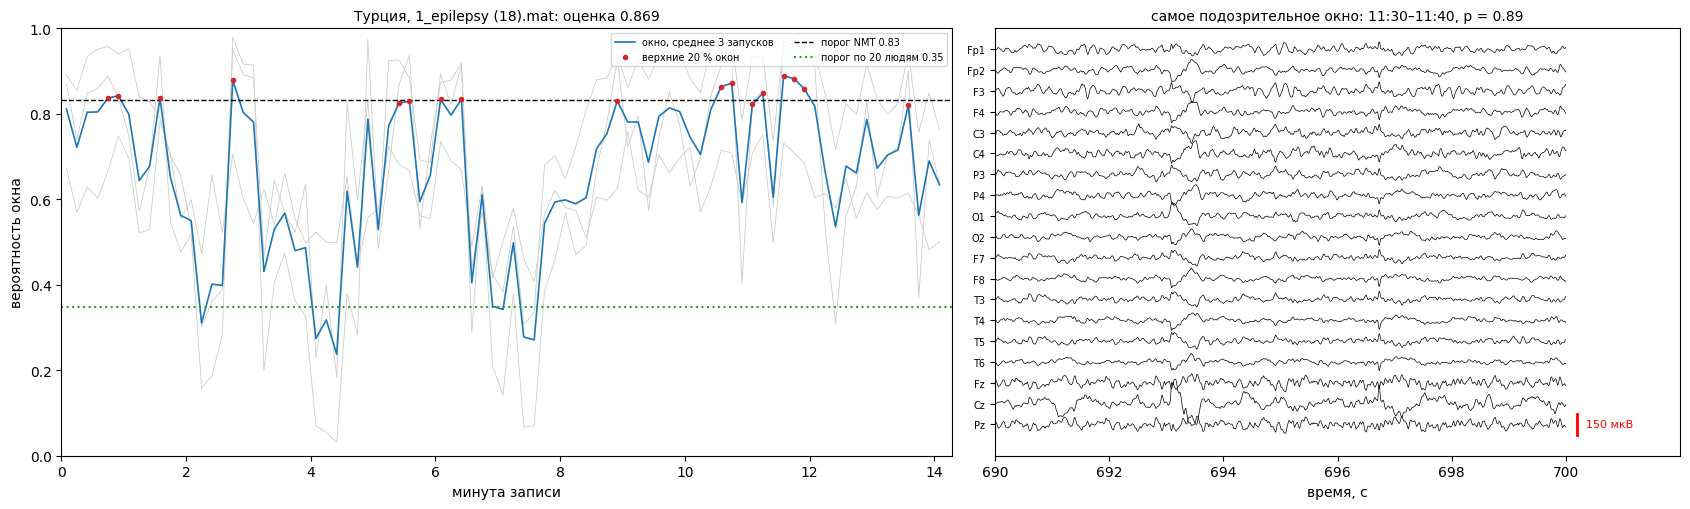

этап,чтение файла,подготовка и окна,"модель, 3 запуска",картинки
секунды,1.5,0.6,89.6,0.6


всего на запись: 92 с (загрузка моделей один раз при запуске: 37 с)


In [9]:
NICE = [10, 20, 25, 50, 75, 100, 150, 200, 300, 500, 1000]
def plot_time(ax, P, ds, title):
    k = P.shape[1]; x = (np.arange(k) * SEG + SEG / 2) / 60; ens = P.mean(0)
    for p in P:
        ax.plot(x, p, color="0.8", lw=0.6)
    ax.plot(x, ens, color="C0", lw=1.2, label="окно, среднее 3 запусков")
    top = np.argsort(ens)[::-1][:int(np.ceil(0.2 * k))]
    ax.scatter(x[top], ens[top], s=9, color="C3", zorder=3, label="верхние 20 % окон")
    ax.axhline(THR_NMT, ls="--", color="k", lw=1, label=f"порог NMT {THR_NMT:.2f}")
    if ds in THR_LOCAL:
        ax.axhline(THR_LOCAL[ds], ls=":", color="C2", lw=1.5, label=f"порог по 20 людям {THR_LOCAL[ds]:.2f}")
    ax.set_ylim(0, 1); ax.set_xlim(0, x[-1] + 0.2); ax.set_xlabel("минута записи"); ax.set_ylabel("вероятность окна")
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7, loc="upper right", ncol=2)
    return int(np.argmax(ens))

def plot_signal(ax, X, w, title, step=None):
    seg = X[:, w * L:(w + 1) * L]; seg = seg - seg.mean(1, keepdims=True)
    if step is None:
        need = np.percentile(np.abs(seg), 99.5) * 1.5
        step = next((n for n in NICE if n >= need), NICE[-1])
    t = w * SEG + np.arange(seg.shape[1]) / SF
    for i in range(19):
        ax.plot(t, seg[i] - i * step, lw=0.5, color="k")
    ax.set_yticks(-np.arange(19) * step); ax.set_yticklabels(EL, fontsize=7)
    x0 = t[-1] + 0.2
    ax.plot([x0, x0], [-18.5 * step, -17.5 * step], color="r", lw=2)
    ax.text(x0 + 0.15, -18 * step, f"{step} мкВ", color="r", fontsize=8, va="center")
    ax.set_xlim(t[0], x0 + 1.8); ax.set_ylim(-19.5 * step, step); ax.set_xlabel("время, с"); ax.set_title(title, fontsize=10)
    return step

def show_record(ds, rid, X, P, score):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw=dict(width_ratios=[1.3, 1]))
    w = plot_time(a1, P, ds, f"{NAME[ds]}, {rid}: оценка {score:.3f}")
    plot_signal(a2, X, w, f"самое подозрительное окно: {w*SEG//60}:{w*SEG%60:02d}–{(w*SEG+SEG)//60}:{(w*SEG+SEG)%60:02d}, p = {P.mean(0)[w]:.2f}")
    plt.tight_layout(); plt.show()

t0 = time.time()
show_record(DS, RID, X, P, SCORE)
TIMES["картинки"] = time.time() - t0
display(pd.DataFrame({"этап": list(TIMES), "секунды": [round(v, 1) for v in TIMES.values()]}).set_index("этап").T)
print(f"всего на запись: {sum(TIMES.values()):.0f} с (загрузка моделей один раз при запуске: {T_LOAD:.0f} с)")

Средний референт, полоса 0,3–75 Гц; красная черта — масштаб в мкВ. Справа — сигнал в окне с самой высокой вероятностью (среднее 3 запусков).

## 3. Подготовленные записи для показа
Выбраны по готовым оценкам из прошлых прогонов, с запасом от порога, и не входят в 20 людей, по которым настроен местный порог. Группы (TP — верно найден больной, TN — верно распознан здоровый, FP — ложная тревога, FN — пропуск) — при пороге по 20 людям.

In [10]:
show_cases = CASES.assign(больница=CASES.dataset.map(NAME), диагноз=CASES.y.map({1: "эпилепсия", 0: "здоров"}),
                          порог_NMT=CASES.verdict_nmt.map({1: "подозрение", 0: "норма"}), порог_20=CASES.verdict_local.map({1: "подозрение", 0: "норма"}))
display(show_cases[["key", "больница", "record", "диагноз", "score_saved", "порог_NMT", "порог_20", "group_local", "dur_min", "amp_uv", "note"]]
        .rename(columns={"key": "ключ", "record": "запись", "score_saved": "оценка", "group_local": "группа", "dur_min": "мин", "amp_uv": "СКО, мкВ", "note": "что видно"})
        .set_index("ключ"))

,больница,запись,диагноз,оценка,порог_NMT,порог_20,группа,мин,"СКО, мкВ",что видно
ключ,,,,,,,,,,
TP1,Турция,1_epilepsy (18).mat,эпилепсия,0.869,подозрение,подозрение,TP,14.2,86.3,верно найден больной (выше обоих порогов)
TP2,Турция,1_epilepsy (16).mat,эпилепсия,0.783,норма,подозрение,TP,14.2,79.3,верно найден больной
TN1,Турция,2_Normal (51).mat,здоров,0.091,норма,норма,TN,17.0,9.8,верно распознан здоровый
TN2,Турция,2_Normal (46).mat,здоров,0.144,норма,норма,TN,18.2,15.4,верно распознан здоровый
FP1,Турция,2_Normal (5).mat,здоров,0.616,норма,подозрение,FP,20.8,34.6,"ложная тревога: высокая амплитуда, медленные волны в лобных отведениях"
FP2,Турция,2_Normal (54).mat,здоров,0.446,норма,подозрение,FP,19.8,8.5,ложная тревога: короткий подозрительный отрезок около 10-й минуты
FN1,Турция,1_epilepsy (7).mat,эпилепсия,0.152,норма,норма,FN,18.0,10.2,"пропуск: низкая амплитуда, оценка низкая по всей записи"
FN2,Турция,1_epilepsy (12).mat,эпилепсия,0.258,норма,норма,FN,18.5,17.1,пропуск
EP1,EpiEEG-60,Abnormal_Patient_40.EEG_Patient_40,эпилепсия,0.919,подозрение,подозрение,TP,31.7,74.3,"EpiEEG-60: больной с размеченными разрядами, найден"


**Оценка записи: 0.616** (среднее верхних 20 % окон, 3 запуска)
- порог с NMT (0.832): **норма**
- порог по 20 людям больницы «Турция» (0.348): **подозрение на эпилепсию**
- на самом деле: **здоров(а)**; сохранённая оценка из прошлого прогона 0.616

*124 окон, 135 с*

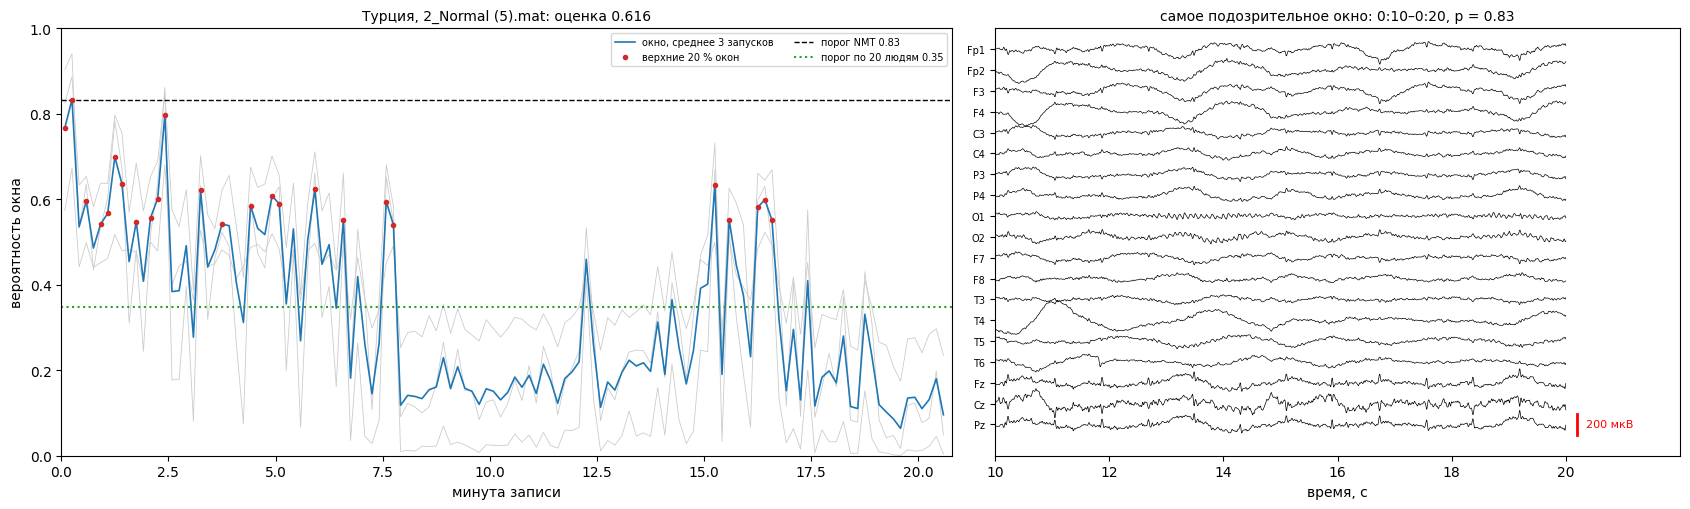

0.6159981886545817

In [11]:
def run_record(rec):
    # весь раздел 2 одной функцией: чтение -> подготовка -> окна -> 3 запуска -> вердикт -> картинки
    ds, rid = resolve(rec); t0 = time.time()
    X = prepare(ds, read_raw(ds, rid)); W = cut(X); P = predict(W); s = record_score(P)
    display(Markdown(verdict_md(ds, rid, s) + f"\n\n*{len(W)} окон, {time.time()-t0:.0f} с*"))
    show_record(ds, rid, X, P, s)
    return s

run_record("FP1")    # любой ключ из таблицы

In [12]:
# Проверка: живой вывод совпадает с сохранёнными оценками (на процессоре ~15 мин на все 10 записей, поэтому по умолчанию выключено)
RUN_ALL_CASES = False
if RUN_ALL_CASES:
    chk = []
    for key, ds, rid, saved in CASES[["key", "dataset", "record", "score_saved"]].itertuples(index=False):
        t0 = time.time(); X_ = prepare(ds, read_raw(ds, rid)); W_ = cut(X_); s = record_score(predict(W_))
        chk.append(dict(ключ=key, запись=rid, сохранённая=saved, сейчас=round(s, 3), разница=round(s - saved, 3),
                        порог_20=("подозрение" if s >= THR_LOCAL[ds] else "норма"), окон=len(W_), секунд=round(time.time() - t0)))
        print(chk[-1], flush=True)
    display(pd.DataFrame(chk).set_index("ключ"))

## 3а. Вторая модель: EEG-DINO v2 и пара с REVE на той же записи
EEG-DINO дообучена заново 02.11 с сохранением весов. Здесь обе модели считают одну запись на 60 равномерно взятых окнах — так же, как в итоговых таблицах. Пара — среднее двух оценок.

In [13]:
DINO_DIR = os.path.dirname(find("eegdino_v2_seed0.pt"))    # выход ядра zakharsann/h1-eegdino-v2
sys.path.insert(0, DINO_DIR)
from eegdino_v2_model import DinoNet, dino_input, EL as EL_DINO
assert list(EL_DINO) == list(EL), "порядок каналов у моделей разный"
t0 = time.time()
DINOS = []
for seed in [0, 1, 2]:
    ck = torch.load(f"{DINO_DIR}/eegdino_v2_seed{seed}.pt", map_location="cpu", weights_only=False)
    m = DinoNet(); m.load_state_dict(ck["state_dict"]); DINOS.append(m.to(DEV).eval())
n_par_d = sum(p.numel() for p in DINOS[0].parameters())
print(f"EEG-DINO v2: параметров в одной модели {n_par_d/1e6:.1f} млн (REVE {n_par/1e6:.1f} млн) | загрузка 3 моделей {time.time()-t0:.0f} с")

PP = pd.read_csv(f"{ASSETS}/eegdino_v2_per_person.csv")     # сохранённые оценки REVE v4, EEG-DINO v2 и пары, 60 окон
THR_PAIR = {ds: calib(PP[PP.dataset == ds].rename(columns={"ens_reve4_dino2": "score"}))[0] for ds in ["turkey", "epieeg60"]}

def predict_dino(W, bs=64):
    x = dino_input(W); out = []
    with torch.no_grad(), torch.autocast(**AMP):
        for m in DINOS:
            out.append(torch.cat([torch.sigmoid(m(x[b:b + bs].to(DEV)).float()).cpu() for b in range(0, len(x), bs)]).numpy())
    return np.stack(out)

def run_pair(rec):
    ds, rid = resolve(rec); t0 = time.time()
    W = cut(prepare(ds, read_raw(ds, rid)))
    W = W[np.unique(np.linspace(0, len(W) - 1, 60).astype(int))] if len(W) > 60 else W
    t_r = time.time(); s_r = record_score(predict(W)); t_r = time.time() - t_r
    t_d = time.time(); s_d = record_score(predict_dino(W)); t_d = time.time() - t_d
    s = (s_r + s_d) / 2
    saved = PP[(PP.dataset == ds) & (PP.id == rid)].iloc[0]
    v = "**подозрение на эпилепсию**" if s >= THR_PAIR[ds] else "**норма**"
    display(Markdown(f"**{rid}** — на самом деле **{'эпилепсия' if saved.y == 1 else 'здоров(а)'}**\n\n"
                     f"| | оценка | сохранённая | время на {len(W)} окон |\n|---|---|---|---|\n"
                     f"| REVE v4 | {s_r:.3f} | {saved.reve4_ens_prob:.3f} | {t_r:.0f} с |\n"
                     f"| EEG-DINO v2 | {s_d:.3f} | {saved.dino2_ens_prob:.3f} | {t_d:.0f} с |\n"
                     f"| пара | **{s:.3f}** | {saved.ens_reve4_dino2:.3f} | |\n\n"
                     f"Порог пары по 20 людям больницы «{NAME[ds]}» ({THR_PAIR[ds]:.3f}): {v}"))

embedding_medium.py:   0%|          | 0.00/3.33k [00:00<?, ?B/s]

transformer.py:   0%|          | 0.00/7.66k [00:00<?, ?B/s]

EEG-DINO v2: параметров в одной модели 34.4 млн (REVE 71.7 млн) | загрузка 3 моделей 14 с


In [14]:
run_pair("TP1")    # любой ключ из таблицы раздела 3

**1_epilepsy (18).mat** — на самом деле **эпилепсия**

| | оценка | сохранённая | время на 60 окон |
|---|---|---|---|
| REVE v4 | 0.864 | 0.865 | 63 с |
| EEG-DINO v2 | 0.662 | 0.662 | 33 с |
| пара | **0.763** | 0.763 | |

Порог пары по 20 людям больницы «Турция» (0.397): **подозрение на эпилепсию**

## 4. Кривые обучения
Все модели дообучались на NMT train; после каждой эпохи считался ROC AUC на отложенных 15 % NMT train (модель их не видит). Брались веса эпохи с лучшим ROC AUC отложенных (кружок); обучение останавливалось, если ROC AUC не рос 2 эпохи подряд. В прошлых блокнотах по эпохам сохранялись только потери обучения и ROC AUC отложенных; потери на отложенных есть у EEG-DINO v2 (ниже) и у REVE v4 (отдельный прогон, тоже ниже).

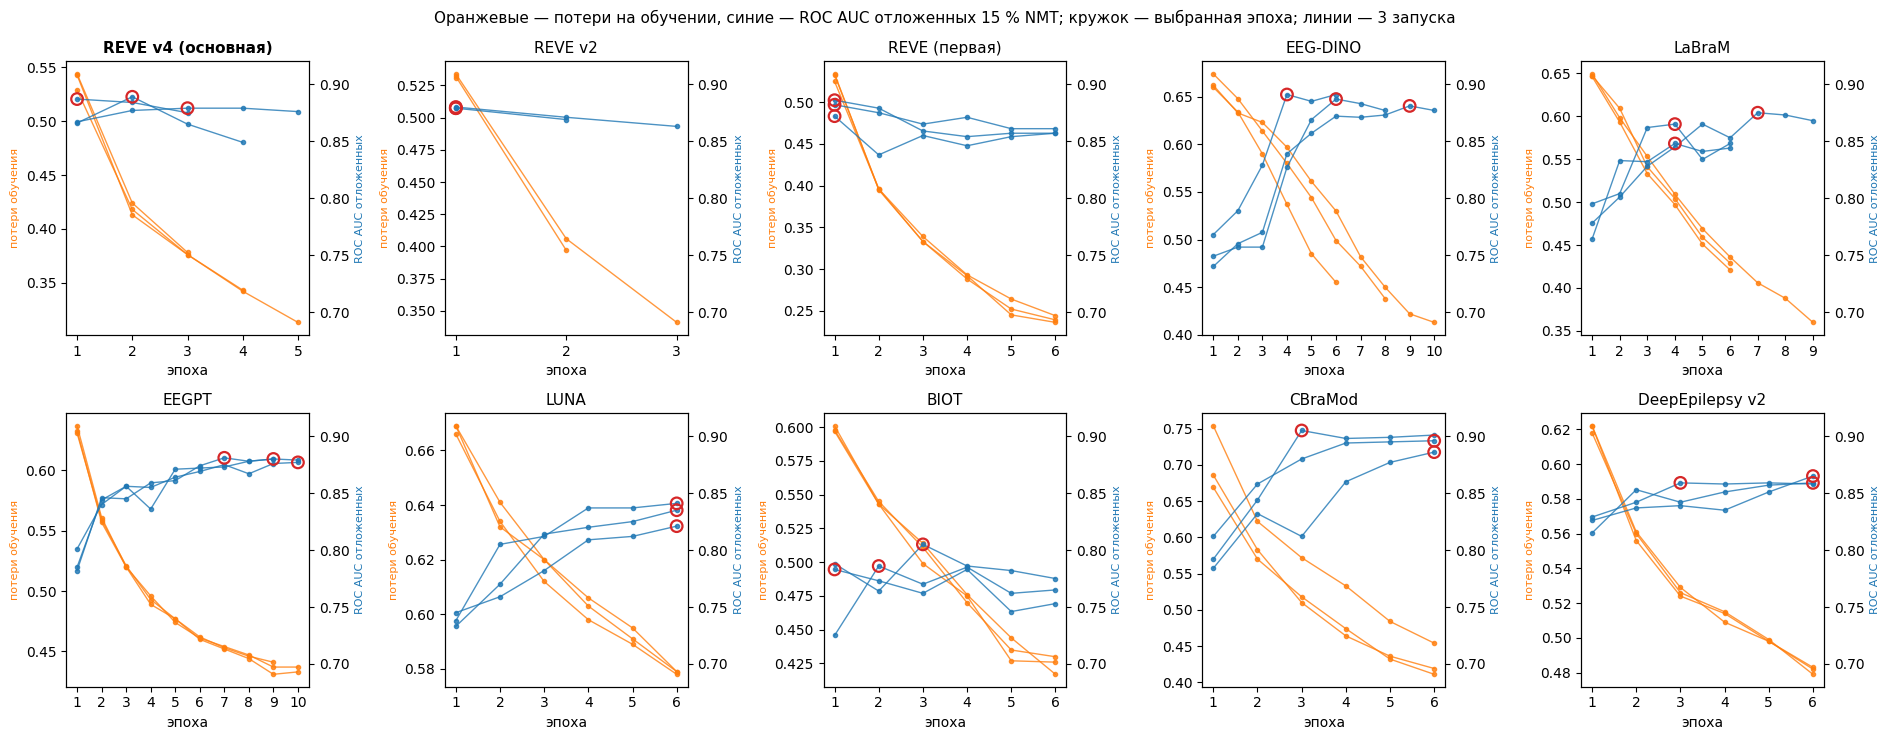

,выбранные эпохи,всего эпох,лучший ROC AUC отложенных,потери: 1-я эпоха → последняя
model,,,,
REVE v4 (основная),"3, 1, 2","5, 3, 4",0.885,0.54 → 0.34
REVE v2,"1, 1, 1","1, 2, 3",0.879,0.53 → 0.42
REVE (первая),"1, 1, 1","6, 6, 6",0.880,0.53 → 0.24
EEG-DINO,"4, 6, 9","6, 8, 10",0.886,0.67 → 0.44
LaBraM,"4, 7, 4","6, 9, 6",0.863,0.65 → 0.40
EEGPT,"7, 10, 9","9, 10, 10",0.879,0.63 → 0.44
LUNA,"6, 6, 6","6, 6, 6",0.832,0.67 → 0.58
BIOT,"3, 2, 1","6, 6, 6",0.791,0.60 → 0.42
CBraMod,"3, 6, 6","6, 6, 6",0.896,0.70 → 0.43


In [15]:
H = pd.read_csv(f"{ASSETS}/train_history.csv")
models = list(H.model.unique())
fig, axes = plt.subplots(2, 5, figsize=(19, 7.5))
for ax, name in zip(axes.flat, models):
    d = H[H.model == name]; ax2 = ax.twinx()
    for s, g in d.groupby("seed"):
        ax.plot(g.epoch, g.train_loss, color="C1", marker=".", lw=1, alpha=0.8)
        ax2.plot(g.epoch, g.val_auc, color="C0", marker=".", lw=1, alpha=0.8)
        c = g[g.chosen == 1]
        ax2.scatter(c.epoch, c.val_auc, s=70, facecolors="none", edgecolors="C3", lw=1.6, zorder=3)
    ax.set_title(name, fontsize=11, fontweight="bold" if "v4" in name else None)
    ax.set_xlabel("эпоха"); ax.set_xticks(range(1, d.epoch.max() + 1))
    ax.set_ylabel("потери обучения", color="C1", fontsize=8); ax2.set_ylabel("ROC AUC отложенных", color="C0", fontsize=8)
    ax2.set_ylim(0.68, 0.92)
fig.suptitle("Оранжевые — потери на обучении, синие — ROC AUC отложенных 15 % NMT; кружок — выбранная эпоха; линии — 3 запуска", fontsize=11)
plt.tight_layout(); plt.show()

tab = H.groupby("model", sort=False).apply(lambda d: pd.Series({
    "выбранные эпохи": ", ".join(str(e) for e in d[d.chosen == 1].sort_values("seed").epoch),
    "всего эпох": ", ".join(str(n) for n in d.groupby("seed").epoch.max()),
    "лучший ROC AUC отложенных": f"{d[d.chosen == 1].val_auc.mean():.3f}",
    "потери: 1-я эпоха → последняя": f"{d[d.epoch == 1].train_loss.mean():.2f} → {d.groupby('seed').train_loss.last().mean():.2f}"}))
display(tab)

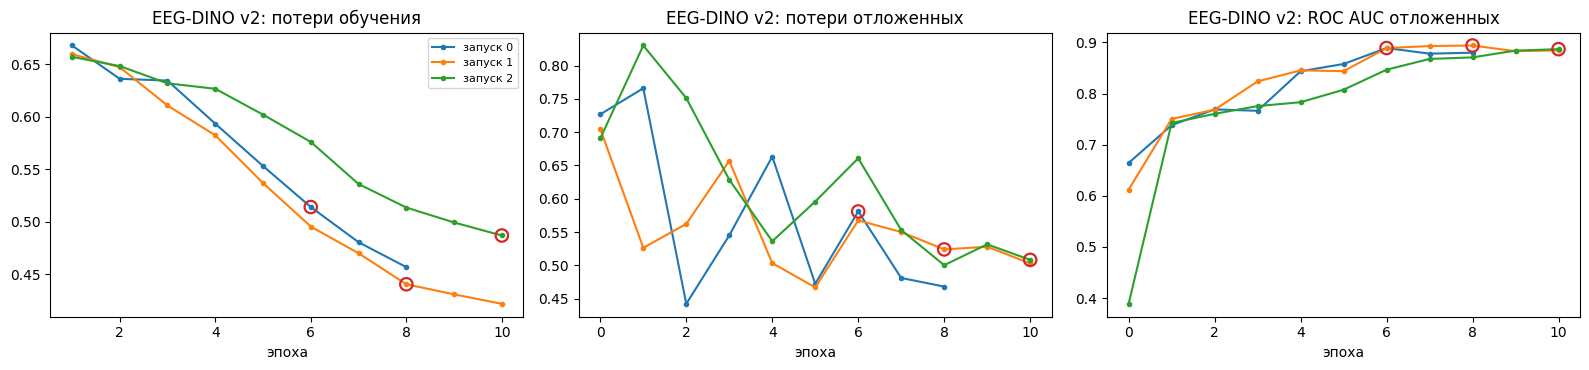

In [16]:
# EEG-DINO v2 (02.11): сохранены полные кривые — потери обучения, потери и ROC AUC отложенных; эпоха 0 — до обучения
E = pd.read_csv(f"{ASSETS}/eegdino_v2_curves.csv")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for col, ax, lab in [("train_loss", axes[0], "потери обучения"), ("val_loss", axes[1], "потери отложенных"), ("val_auc", axes[2], "ROC AUC отложенных")]:
    for s, g in E.groupby("seed"):
        ax.plot(g.epoch, g[col], marker=".", label=f"запуск {s}")
        b = g[g.best == 1]; ax.scatter(b.epoch, b[col], s=80, facecolors="none", edgecolors="C3", lw=1.6, zorder=3)
    ax.set_title(f"EEG-DINO v2: {lab}"); ax.set_xlabel("эпоха")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### REVE v4: потери на обучении и на отложенной части (отдельный прогон 04.11)
В основном прогоне REVE v4 потери на отложенной части не сохранялись, поэтому 04.11 обучение повторили с теми же настройками, но без ранней остановки (ровно 6 эпох, ядро `zakharsann/h1-reve-v4-loss`). Веса для показа — прежние. Потери на отложенной части — с уравненными классами: там мало больных, а на обучении классы уравнены выборкой, поэтому так кривые сравнимы.

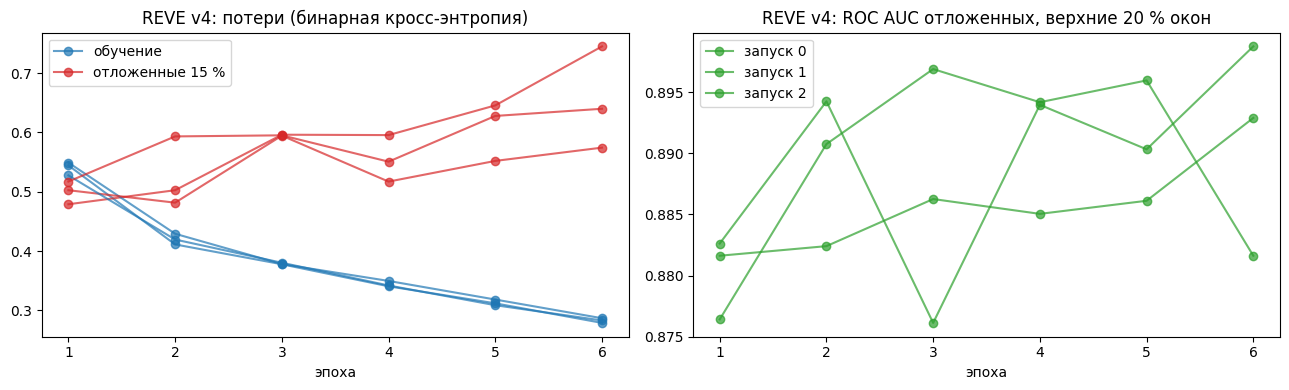

train_loss  val_loss  val_loss_balanced  val_auc  val_auc_top20
seed epoch                                                                 
0    1           0.545     0.544              0.479    0.878          0.876
     2           0.411     0.603              0.503    0.879          0.891
     3           0.378     0.832              0.596    0.881          0.897
     4           0.341     0.698              0.596    0.876          0.894
     5           0.312     0.787              0.646    0.869          0.896
     6           0.279     0.994              0.745    0.857          0.882
1    1           0.549     0.560              0.503    0.874          0.883
     2           0.429     0.563              0.482    0.895          0.894
     3           0.378     0.797              0.595    0.859          0.876
     4           0.350     0.612              0.517    0.875          0.894
     5           0.318     0.700              0.552    0.891          0.890
     6           0.287     0.647              0.574    0.877          0.899
2    1           0.528     0.694              0.517    0.877          0.882
     2           0.420     0.882              0.593    0.880          0.882
     3           0.380     0.853              0.595    0.869          0.886
     4           0.342     0.597              0.551    0.855          0.885
     5           0.309     0.883              0.628    0.874          0.886
     6           0.283     0.729              0.640    0.871          0.893

In [17]:
C = pd.read_csv(f"{ASSETS}/reve_v4_loss_curves.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for s, g in C.groupby("seed"):
    ax[0].plot(g.epoch, g.train_loss, "-o", color="C0", alpha=.7, label="обучение" if s == 0 else None)
    ax[0].plot(g.epoch, g.val_loss_balanced, "-o", color="C3", alpha=.7, label="отложенные 15 %" if s == 0 else None)
    ax[1].plot(g.epoch, g.val_auc_top20, "-o", color="C2", alpha=.7, label=f"запуск {s}")
ax[0].set(title="REVE v4: потери (бинарная кросс-энтропия)", xlabel="эпоха"); ax[0].legend()
ax[1].set(title="REVE v4: ROC AUC отложенных, верхние 20 % окон", xlabel="эпоха"); ax[1].legend()
plt.tight_layout(); plt.show()
display(C.round(3).set_index(["seed", "epoch"]))

**Вывод по потерям.**
- **REVE v4 переобучается быстро, и теперь это видно по потерям.** Потери на обучении падают всё время: в среднем 0,54 → 0,28 за 6 эпох. Потери на отложенной части минимальны на 1–2-й эпохе (0,48–0,52), затем растут: к 6-й эпохе 0,57–0,75. Поэтому нужна ранняя остановка, и она у нас есть: рабочие веса взяты с лучшей эпохи.
- **При этом разделение классов не портится:** ROC AUC отложенных (верхние 20 % окон) остаётся 0,88–0,90 до 6-й эпохи. То есть порядок людей сохраняется, а модель становится слишком уверенной в своих вероятностях. Это может быть одной из причин, почему порог не переносится в другую больницу, но отдельно мы это не проверяли.
- **Как было раньше.** В v2 модель видела одни и те же 8 окон каждой записи, и лучшей всегда была первая эпоха. В v4 на каждой эпохе берутся новые случайные окна — лучшая эпоха 1–3, но выше 0,88–0,90 на отложенных модель не поднялась.
- **Остальные модели учатся медленнее:** лучшие эпохи 3–10. У LUNA, CBraMod и DeepEpilepsy лучшая эпоха часто последняя (6 из 6), у EEGPT — 9–10 из 10: эти модели могли бы учиться дольше. BIOT переобучается так же рано, как REVE.
- **EEG-DINO v2:** потери отложенных скачут от эпохи к эпохе, ROC AUC растёт до 6–10-й эпохи; явного переобучения за 10 эпох нет.
- Лучший ROC AUC на отложенных у всех моделей 0,79–0,90. Главный критерий выбора — перенос в другие больницы (раздел 6), а не отложенные NMT.

## 4а. Как EEG-DINO прогнали так быстро
**Мы её не обучали, а дообучали.** Дорогая часть — предобучение на большом архиве ЭЭГ (по странице авторов — более 9000 часов) — сделана авторами. Мы взяли готовые веса кодировщика (загружены все 227 частей). С нуля учится только голова, а кодировщик дообучается вместе с ней с меньшей скоростью (послойное снижение 0,9) и на NMT.

| | EEG-DINO v2 |
|---|---|
| Размер | EEG-DINO-**M**: 34,4 млн параметров (не самая большая версия) |
| Данные на эпоху | 8 окон по 10 с с каждой записи ≈ 15 тыс. окон |
| Эпоха на T4 | **2,2 мин** |
| Один запуск | 8–10 эпох, **18–22 мин** |
| Весь блокнот, 3 запуска | **79 мин** T4 |

Что подтверждает, что модель действительно обучилась: потери падают (кривые в разделе 4), на NMT eval ROC AUC 0,90, запуски воспроизводятся из сохранённых весов (расхождение вероятностей ≤ 1·10⁻⁴).

## 5. Где модель ошибается
Пары «ошибка — верный случай того же класса»: ложная тревога рядом с верно распознанным здоровым, пропуск рядом с найденным больным. Пару подбираем автоматически: в Турции — ближайший по длине записи (возраста в турецком наборе нет), в NMT — ближайший по возрасту. Оценки вдоль записи — сохранённые (модель здесь не запускается), сигнал читается из исходных файлов.

In [18]:
LAB = pd.read_csv(f"{NMT_ROOT}/Labels.csv").drop_duplicates("recordname").set_index("recordname")
SC["age"] = SC.id.map(LAB.age)
ALIAS = {"T7": "T3", "T8": "T4", "P7": "T5", "P8": "T6"}
def norm_ch(ch):
    c = ch.upper().replace("EEG", "").strip()
    for s in ["-REF", "-AVG", "-LE", "-AR"]:
        c = c.replace(s, "")
    return ALIAS.get(c.strip(" -_"), c.strip(" -_"))

def read_nmt(name):
    # NMT: в файлах средний референт, 200 Гц; масштаб в файлах неверный — множитель x100, как в общем наборе
    import mne
    raw = mne.io.read_raw_edf(glob.glob(f"{NMT_ROOT}/**/{name}", recursive=True)[0], preload=True, verbose="ERROR")
    if raw.info["sfreq"] != SF:
        raw.resample(SF)
    names = {norm_ch(c): c for c in raw.ch_names}
    return filt(raw.get_data(picks=[names[e.upper()] for e in EL]) * 1e6 * 100)

def signal(ds, rid):
    return prepare(ds, read_raw(ds, rid)) if ds == "turkey" else read_nmt(rid)

def window_P(ds, rid):
    return WS[(WS.dataset == ds) & (WS.id == rid)].pivot(index="seed", columns="window", values="p").to_numpy()

def partner(ds, rid):
    # тот же класс, верно распознан с запасом 0,05 от порога, не из 20 людей калибровки; ближайший по возрасту (NMT) или длине (Турция)
    thr = THR_LOCAL.get(ds, THR_NMT); e = SC[(SC.dataset == ds) & (SC.id == rid)].iloc[0]
    c = SC[(SC.dataset == ds) & (SC.y == e.y) & (SC.id != rid) & ~SC.id.isin(CAL.get(ds, []))]
    c = c[((c.score >= thr) == (c.y == 1)) & ((c.score - thr).abs() > 0.05)]
    key = (c.age - e.age).abs() * 100 + (c.dur_min - e.dur_min).abs() if ds == "nmt_eval" else (c.dur_min - e.dur_min).abs()
    return c.loc[key.idxmin(), "id"]

def show_pair(ds, rid, title):
    pid = partner(ds, rid); thr = THR_LOCAL.get(ds, THR_NMT)
    rows, sig = [], {}
    for r in [rid, pid]:
        e = SC[(SC.dataset == ds) & (SC.id == r)].iloc[0]
        grp = {(1, 1): "найден", (0, 0): "верно: норма", (0, 1): "ЛОЖНАЯ ТРЕВОГА", (1, 0): "ПРОПУСК"}[(int(e.y), int(e.score >= thr))]
        rows.append({"запись": r, "диагноз": "эпилепсия" if ds == "turkey" and e.y else ("патология" if e.y else "норма"), "результат": grp,
                     "оценка": round(e.score, 3), "СКО записи, мкВ": round(e.amp_uv, 1), "мышечная помеха (доля 20–70 Гц)": round(e.muscle, 3),
                     "мин": round(e.dur_min, 1), "возраст": "нет данных" if np.isnan(e.age) else int(e.age)})
        sig[r] = signal(ds, r)
    display(Markdown(f"### {title}  \n{NAME[ds]}, порог {thr:.3f}"))
    display(pd.DataFrame(rows).set_index("запись"))
    fig, ax = plt.subplots(2, 2, figsize=(17, 9.5), gridspec_kw=dict(height_ratios=[1, 1.6]))
    steps = []
    for j, r in enumerate([rid, pid]):
        P_ = window_P(ds, r)
        w = plot_time(ax[0, j], P_, ds, f"{r}: {rows[j]['результат']}, оценка {rows[j]['оценка']}")
        steps.append((r, w))
    step = max(next((n for n in NICE if n >= np.percentile(np.abs(sig[r][:, w * L:(w + 1) * L]), 99.5) * 1.5), NICE[-1]) for r, w in steps)
    for j, (r, w) in enumerate(steps):
        plot_signal(ax[1, j], sig[r], w, f"{r}: самое подозрительное окно ({w*SEG//60}:{w*SEG%60:02d}), p = {window_P(ds, r).mean(0)[w]:.2f}", step=step)
    plt.tight_layout(); plt.show()

### Турция: ложная тревога рядом с верно распознанным здоровым  
Турция, порог 0.348

,диагноз,результат,оценка,"СКО записи, мкВ",мышечная помеха (доля 20–70 Гц),мин,возраст
запись,,,,,,,
2_Normal (5).mat,норма,ЛОЖНАЯ ТРЕВОГА,0.616,34.6,0.007,20.8,нет данных
2_Normal (14).mat,норма,верно: норма,0.159,9.0,0.061,21.0,нет данных


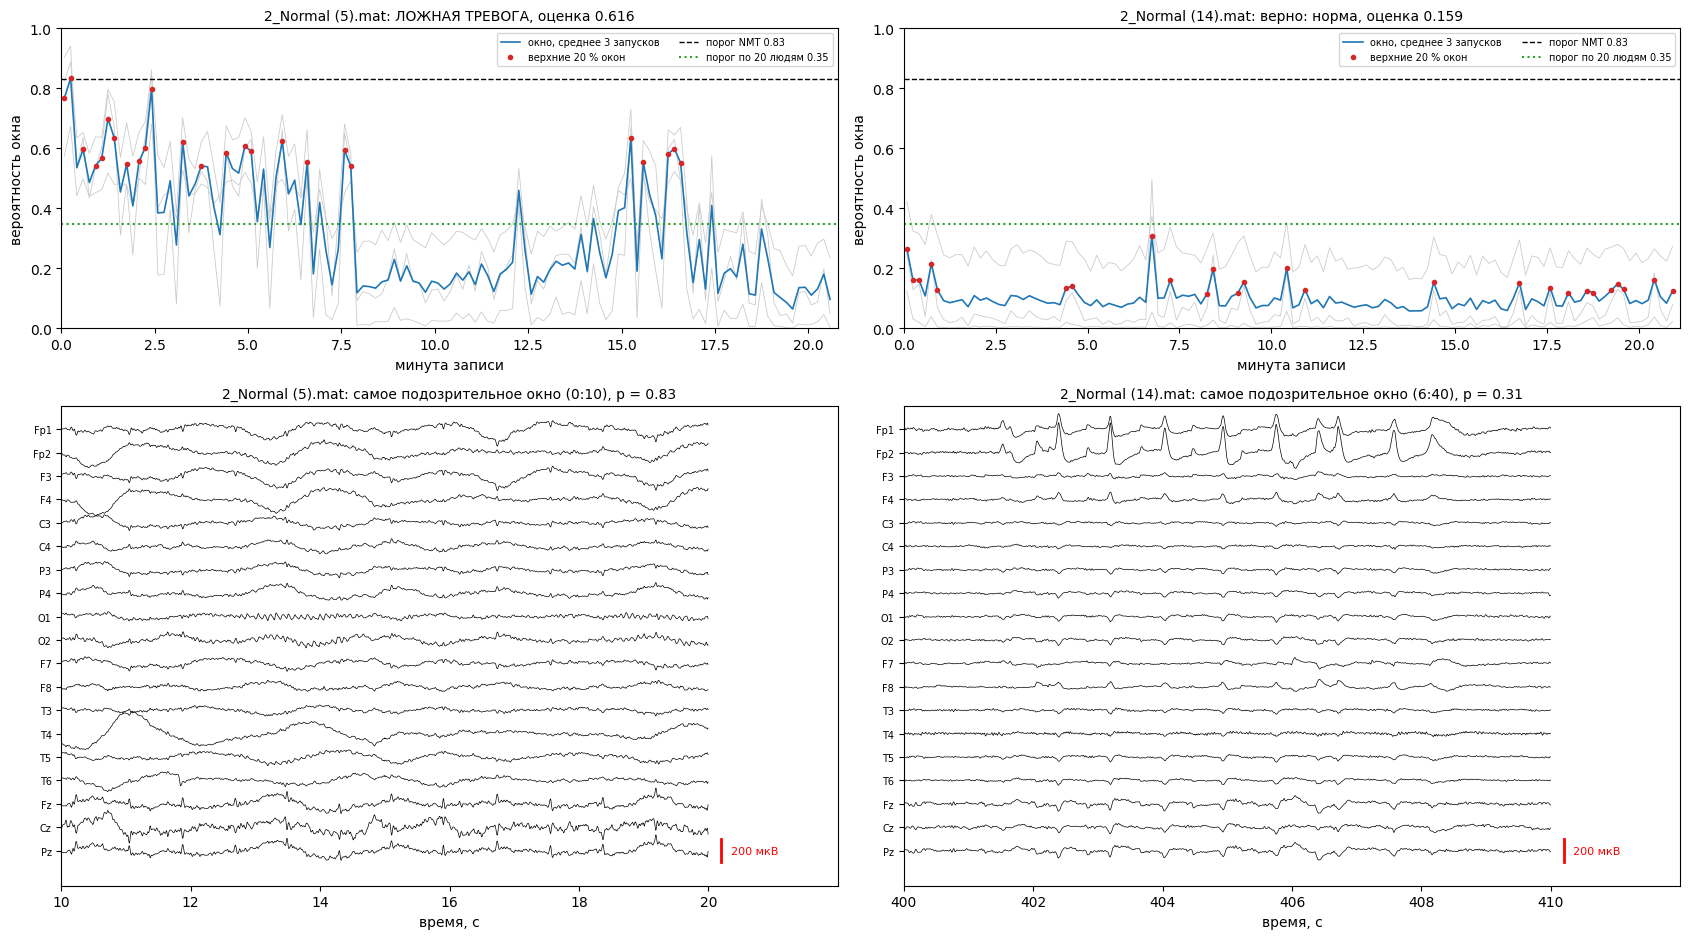

### Турция: пропуск рядом с найденным больным  
Турция, порог 0.348

,диагноз,результат,оценка,"СКО записи, мкВ",мышечная помеха (доля 20–70 Гц),мин,возраст
запись,,,,,,,
1_epilepsy (7).mat,эпилепсия,ПРОПУСК,0.152,10.2,0.041,18.0,нет данных
1_epilepsy (11).mat,эпилепсия,найден,0.428,14.0,0.024,18.2,нет данных


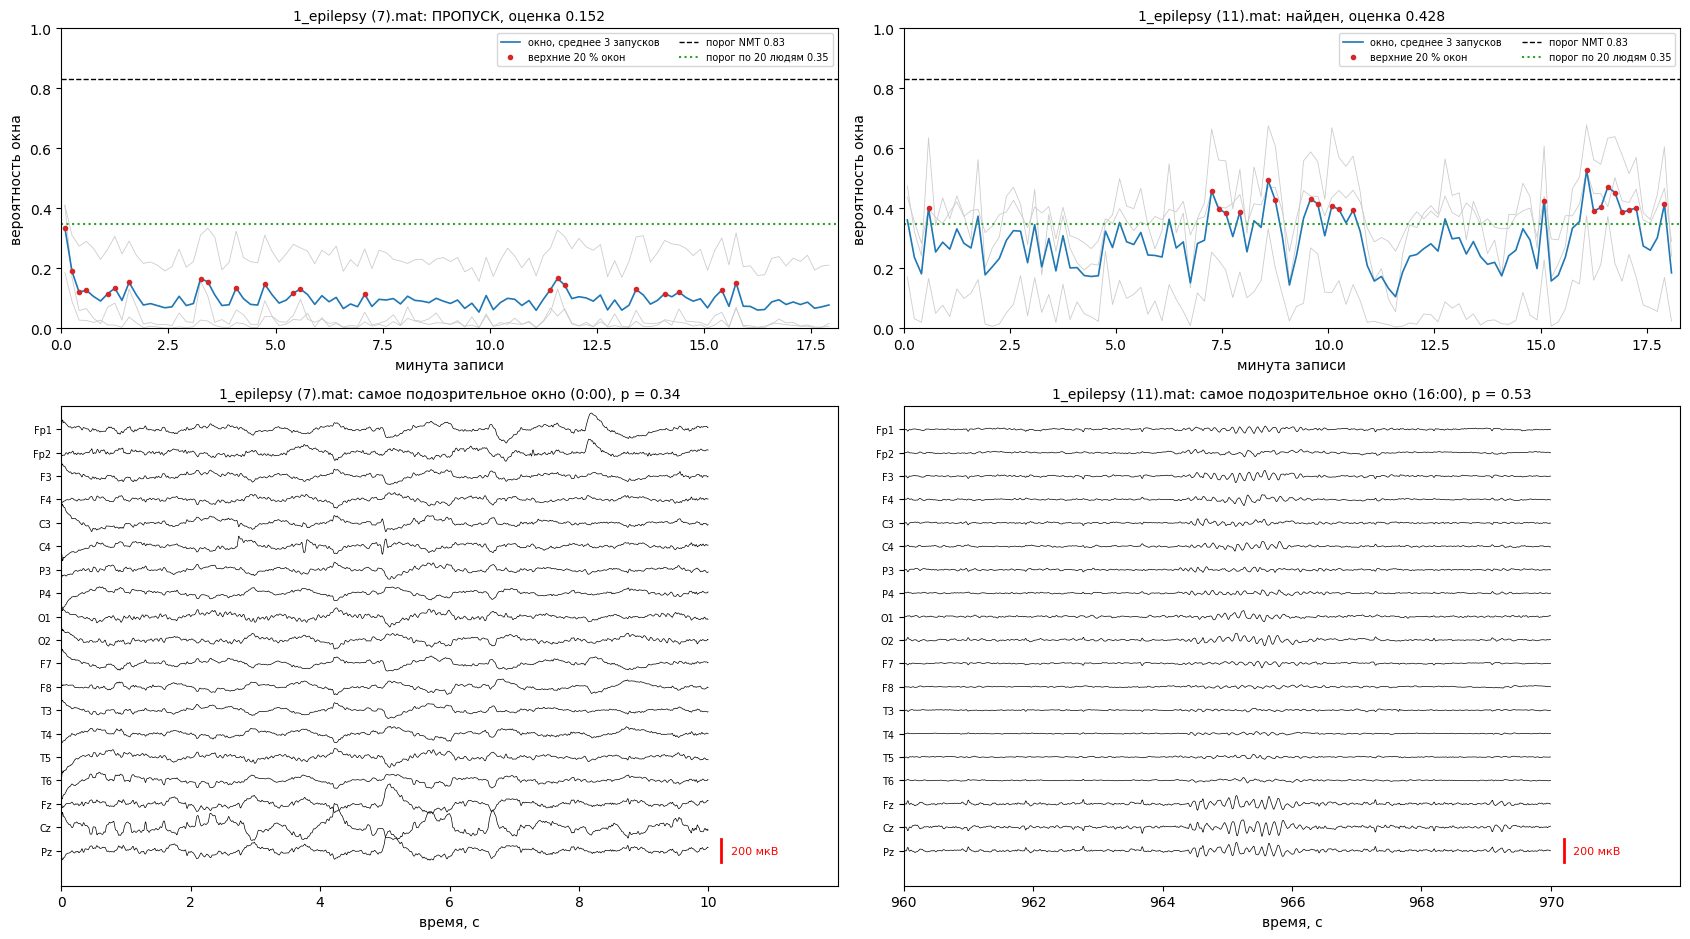

14 с


In [19]:
t0 = time.time()
show_pair("turkey", "2_Normal (5).mat", "Турция: ложная тревога рядом с верно распознанным здоровым")
show_pair("turkey", "1_epilepsy (7).mat", "Турция: пропуск рядом с найденным больным")
print(f"{time.time()-t0:.0f} с")

### NMT eval: ложная тревога рядом с верно распознанной «нормой» близкого возраста  
NMT eval, порог 0.832

,диагноз,результат,оценка,"СКО записи, мкВ",мышечная помеха (доля 20–70 Гц),мин,возраст
запись,,,,,,,
0000044.edf,норма,ЛОЖНАЯ ТРЕВОГА,0.945,45.1,0.008,10.9,4
0000614.edf,норма,верно: норма,0.751,66.4,0.011,9.8,2


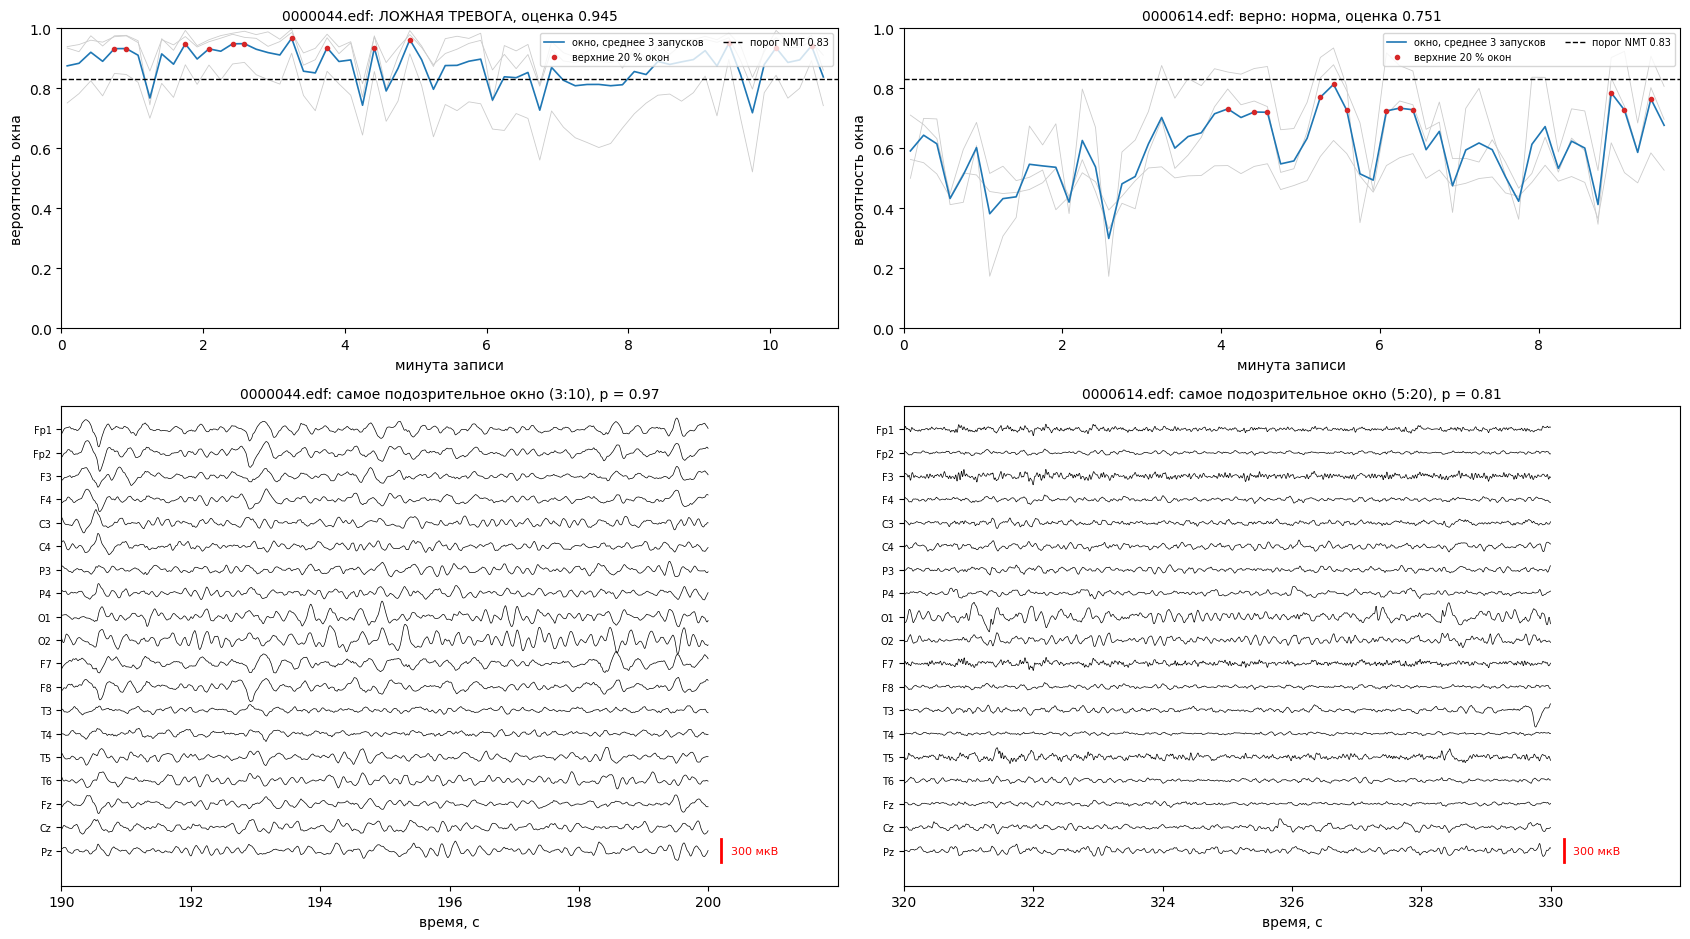

### NMT eval: пропуск рядом с найденной «патологией» близкого возраста  
NMT eval, порог 0.832

,диагноз,результат,оценка,"СКО записи, мкВ",мышечная помеха (доля 20–70 Гц),мин,возраст
запись,,,,,,,
0000896.edf,патология,ПРОПУСК,0.315,6.6,0.052,9.0,36
0000203.edf,патология,найден,0.989,17.5,0.002,9.2,38


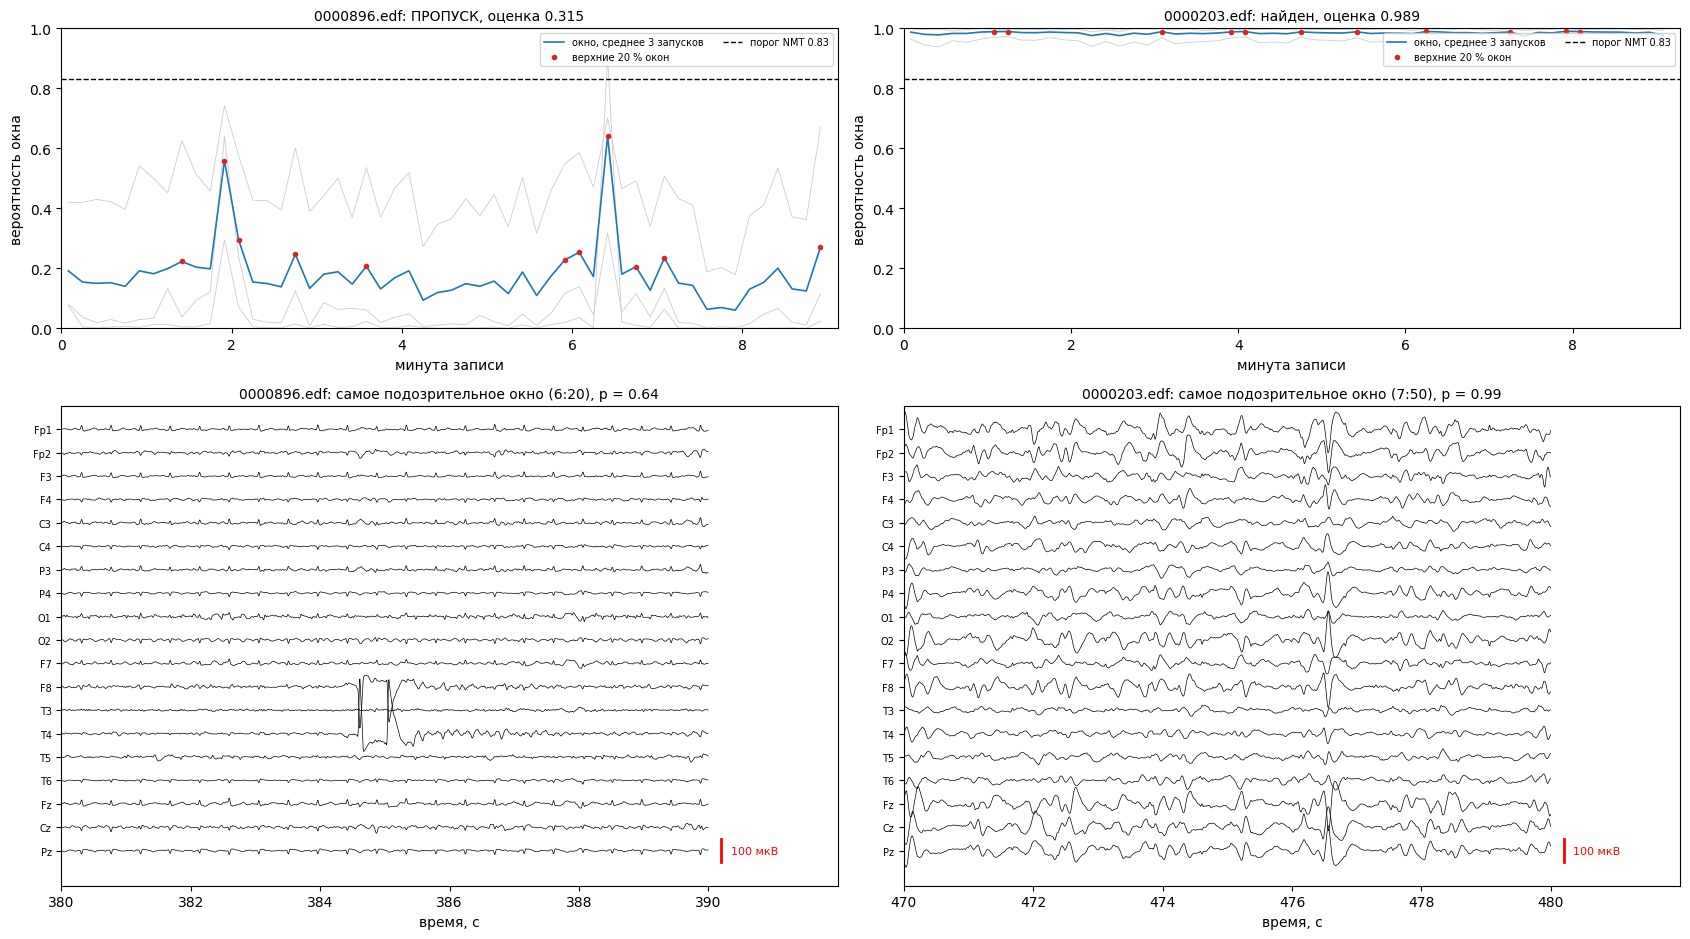

6 с


In [20]:
t0 = time.time()
show_pair("nmt_eval", "0000044.edf", "NMT eval: ложная тревога рядом с верно распознанной «нормой» близкого возраста")
show_pair("nmt_eval", "0000896.edf", "NMT eval: пропуск рядом с найденной «патологией» близкого возраста")
print(f"{time.time()-t0:.0f} с")

Шкала в мкВ у пары общая, чтобы амплитуды можно было сравнить на глаз. У NMT абсолютные мкВ приблизительные (масштаб восстановлен множителем ×100).

В паре ложной тревоги NMT оба ребёнка маленькие (4 и 2 года) и у обоих высокая амплитуда; верная «норма» прошла ниже порога с небольшим запасом. У маленьких детей модель ошибается чаще всего (раздел ниже). В паре пропуска у пропущенного взрослого амплитуда в 2,5 раза ниже (6,6 против 17,5 мкВ), а в самом подозрительном окне — короткий артефакт в F8/T4, а не разряды.

**Ложные тревоги и пропуски против верных случаев того же класса** (отчёт `reports/2026-10-27_reve_errors.md`, порог Юдена внутри набора)

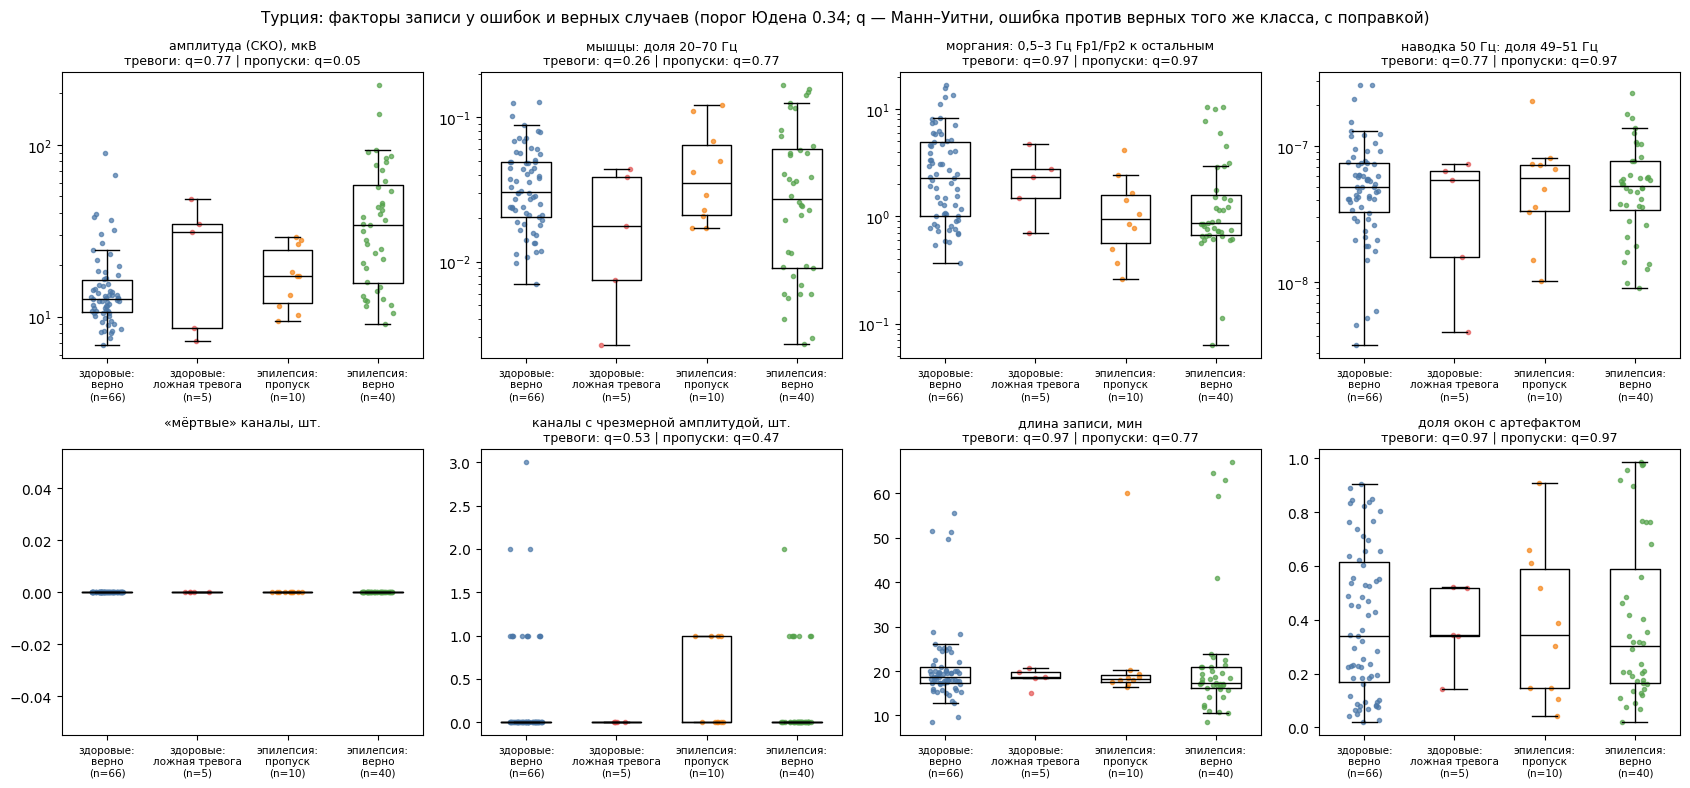

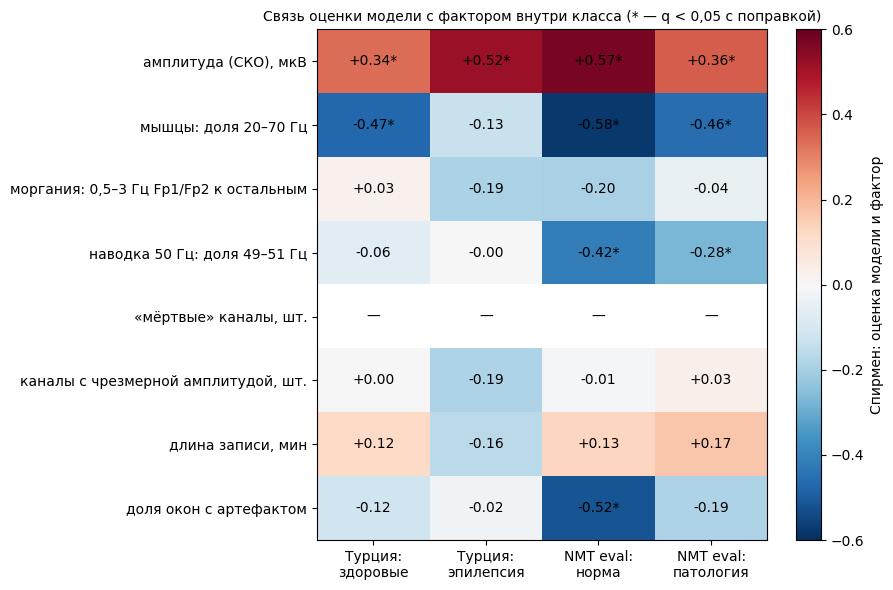

**Возраст на NMT:** ложные тревоги — в основном дети, пропуски — взрослые

,набор,класс,сравнение,n_ошибок,n_верных,медиана_возраста_ошибки,медиана_возраста_верные,медиана_амплитуды_ошибки,медиана_амплитуды_верные,MW_p
0,NMT eval,норма,FP против TN,17,78,8.0,25.5,38.1,16.2,0.0000
1,NMT eval,патология,FN против TP,15,75,31.0,13.0,17.2,32.9,0.0306
2,NMT val (15 % train),норма,FP против TN,46,240,8.5,25.0,28.5,17.2,0.0000
3,NMT val (15 % train),патология,FN против TP,9,40,28.0,8.5,18.9,35.6,0.0097


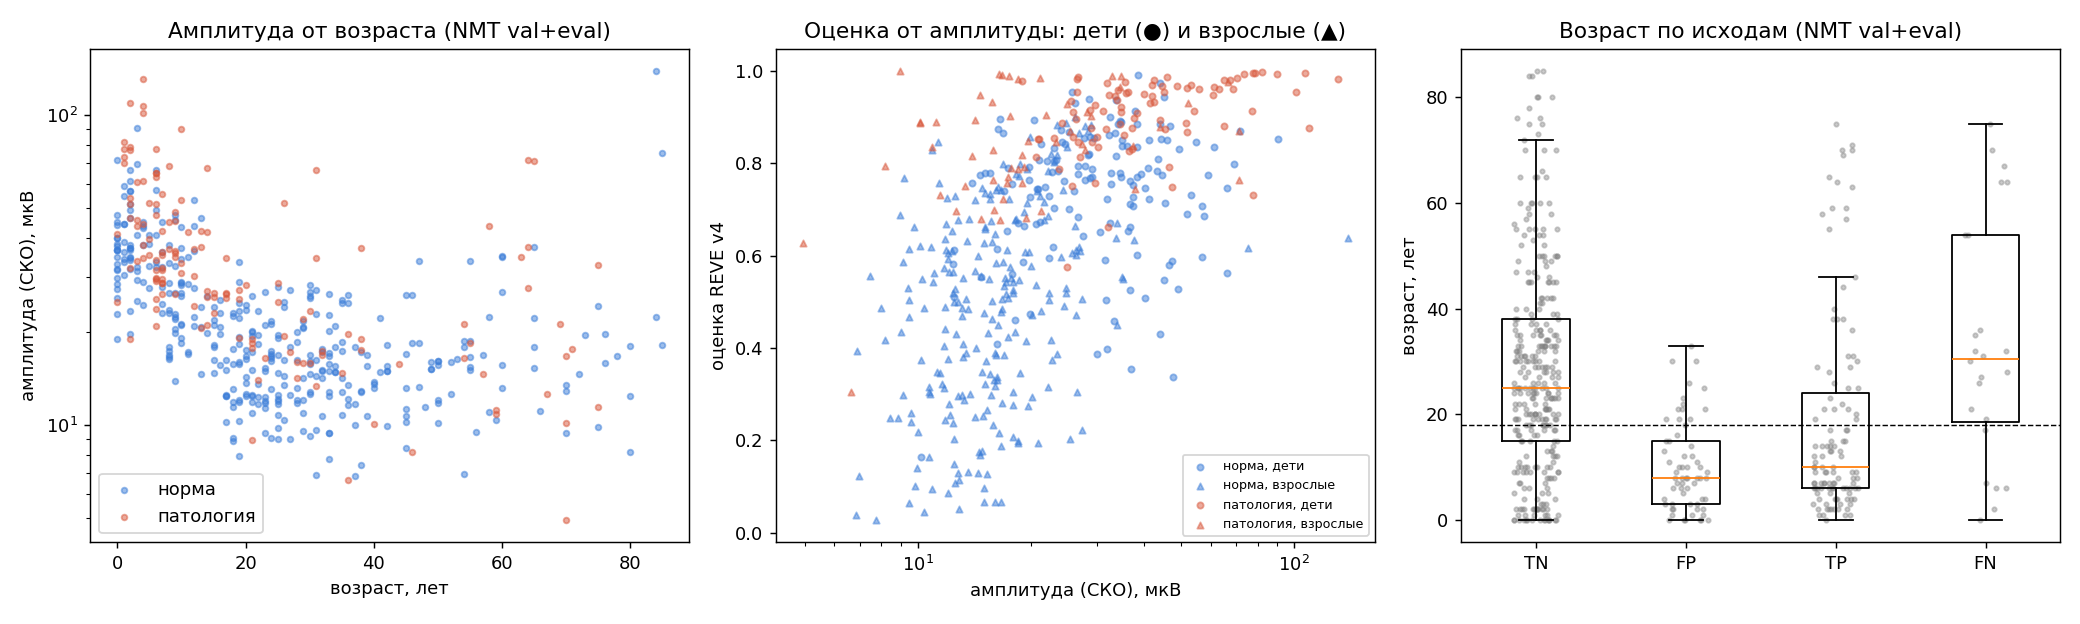

In [21]:
display(Markdown("**Ложные тревоги и пропуски против верных случаев того же класса** (отчёт `reports/2026-10-27_reve_errors.md`, порог Юдена внутри набора)"))
display(Image(f"{ASSETS}/01_factors_turkey.png", width=1000))
display(Image(f"{ASSETS}/03_spearman.png", width=800))
ag = pd.read_csv(f"{ASSETS}/age_check_errors.csv")
display(Markdown("**Возраст на NMT:** ложные тревоги — в основном дети, пропуски — взрослые"))
display(ag[["набор", "класс", "сравнение", "n_ошибок", "n_верных", "медиана_возраста_ошибки", "медиана_возраста_верные",
            "медиана_амплитуды_ошибки", "медиана_амплитуды_верные", "MW_p"]].round(4))
display(Image(f"{ASSETS}/age_check.png", width=1000))

**Выводы (из разбора ошибок 27.10 и проверки возраста):**
1. **Главный фактор — амплитуда записи.** Внутри каждого класса чем выше амплитуда, тем выше оценка (Спирмен +0,34…+0,57), хотя каждое окно нормируется. Ложные тревоги — «нормы» с высокой амплитудой (NMT: 38 мкВ против 16 у верных), пропуски — больные с низкой амплитудой (Турция: 17 против 34 мкВ). Видимо, модель узнаёт амплитуду по форме спектра: в высокоамплитудных записях больше медленных волн.
2. **Возраст объясняет часть этой связи.** У детей амплитуда выше: ложные тревоги на NMT — в основном дети (медиана 8 лет против 25,5), пропуски — взрослые (31 год против 13). С поправкой на возраст связь оценки с амплитудой слабеет с +0,5 до +0,33, но остаётся.
3. **Мышечная помеха снижает оценку**, моргания с ошибками не связаны. Выкидывание артефактных окон качество не улучшило.
4. **Больных без явных разрядов модель узнаёт плохо.** В EpiEEG-60 больные с размеченными разрядами против здоровых — ROC AUC 0,81, без разметки разрядов (7 человек) — 0,60. Это самый трудный случай для гипотезы.
5. Ложных тревог в Турции всего 5 — выводы по ним ненадёжны. Картинки сигнала стоит посмотреть врачу: артефакт это, особенность записи или ошибка разметки.

## 6. Итог: REVE v4 на трёх больницах
Цифры из `h1_eeg/SUMMARY.md` и отчётов (без пересчёта). Ансамбль 3 запусков, оценка записи — среднее верхних 20 % окон; 95% ДИ — бутстреп по людям.

| Больница | Людей | Модель видела при обучении? | ROC AUC (95% ДИ) | Порог с NMT 0,832: сбаланс. accuracy / recall / специфичность | Порог по 20 людям больницы: сбаланс. accuracy |
|---|---|---|---|---|---|
| NMT eval (Пакистан) | 185 (90 патология / 95 норма) | та же больница, другие люди | **0,917** (0,88–0,95) | 0,81 / 0,74 / 0,88 | — |
| Турция | 121 (50 эпилепсия / 71 здоровый) | нет | **0,915** (0,86–0,96) | 0,52 / **0,04** / 1,00 | **0,80** (0,71–0,85) |
| EpiEEG-60 (Бангладеш) | 63 (31 / 32) | нет | **0,761** (0,63–0,88) | 0,70 / 0,61 / 0,78 | 0,69 (0,57–0,78) |

- **Ранжирование переносится, порог — нет.** В Турции ROC AUC такой же, как на NMT, но вероятности «съезжают» вниз: при пороге NMT модель находит 4 % больных. Настройка порога на 20 размеченных людях новой больницы возвращает сбалансированную accuracy 0,80 (ансамбль с EEG-DINO — 0,85).
- **Третья больница заметно труднее** (0,76). Там порог с NMT переносится лучше, а местная настройка не помогает. Модель хорошо находит больных с размеченными разрядами (0,81) и почти не находит больных без них (0,60, n = 7).
- Скорость: запись 20 мин — ~1,2 с на GPU T4 и ~1,5 мин на процессоре (3 запуска).

### REVE v4, EEG-DINO v2 и пара на трёх больницах (ROC AUC, 60 окон, верхние 20 %)

| | NMT eval | Турция | EpiEEG-60 |
|---|---|---|---|
| REVE v4 | 0,913 (0,87–0,95) | 0,923 (0,87–0,97) | 0,761 (0,63–0,88) |
| EEG-DINO v2 | 0,901 (0,85–0,94) | 0,858 (0,78–0,92) | 0,748 (0,62–0,87) |
| **Пара** | **0,920** | **0,936** | 0,756 |

Прирост пары к REVE не значим: +0,007 / +0,013 / −0,005, все интервалы включают 0. Порог по 20 людям в Турции: сбаланс. accuracy пары 0,84 (recall 0,77, специфичность 0,91, precision 0,89), REVE — 0,81.

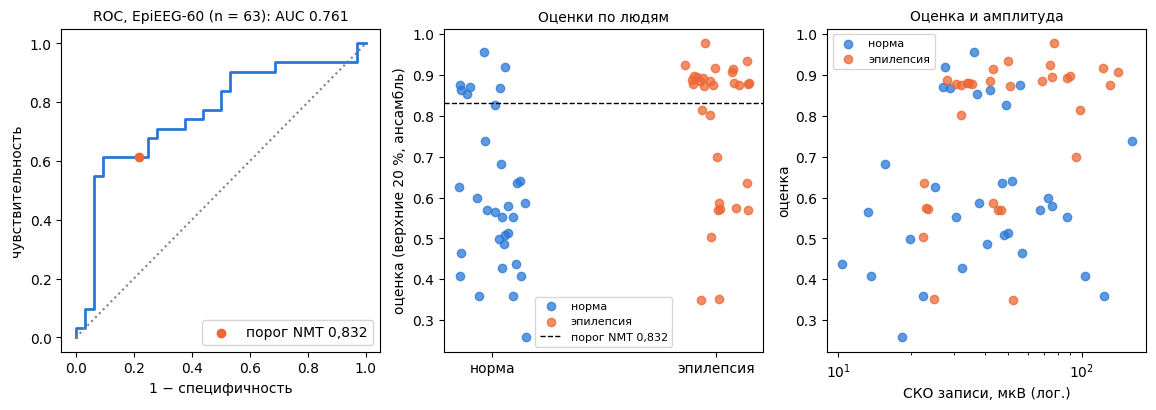

весь блокнот: 7.4 мин на процессоре


In [22]:
display(Image(f"{ASSETS}/epieeg60_reve_v4.png", width=1000))
print(f"весь блокнот: {(time.time()-T_START)/60:.1f} мин на {'GPU' if DEV == 'cuda' else 'процессоре'}")

## 7. Что дают дополнительные записи новой больницы
REVE v4, турецкий набор: 50 одних и тех же проверочных людей, адаптация на N других людях, 10 повторов.

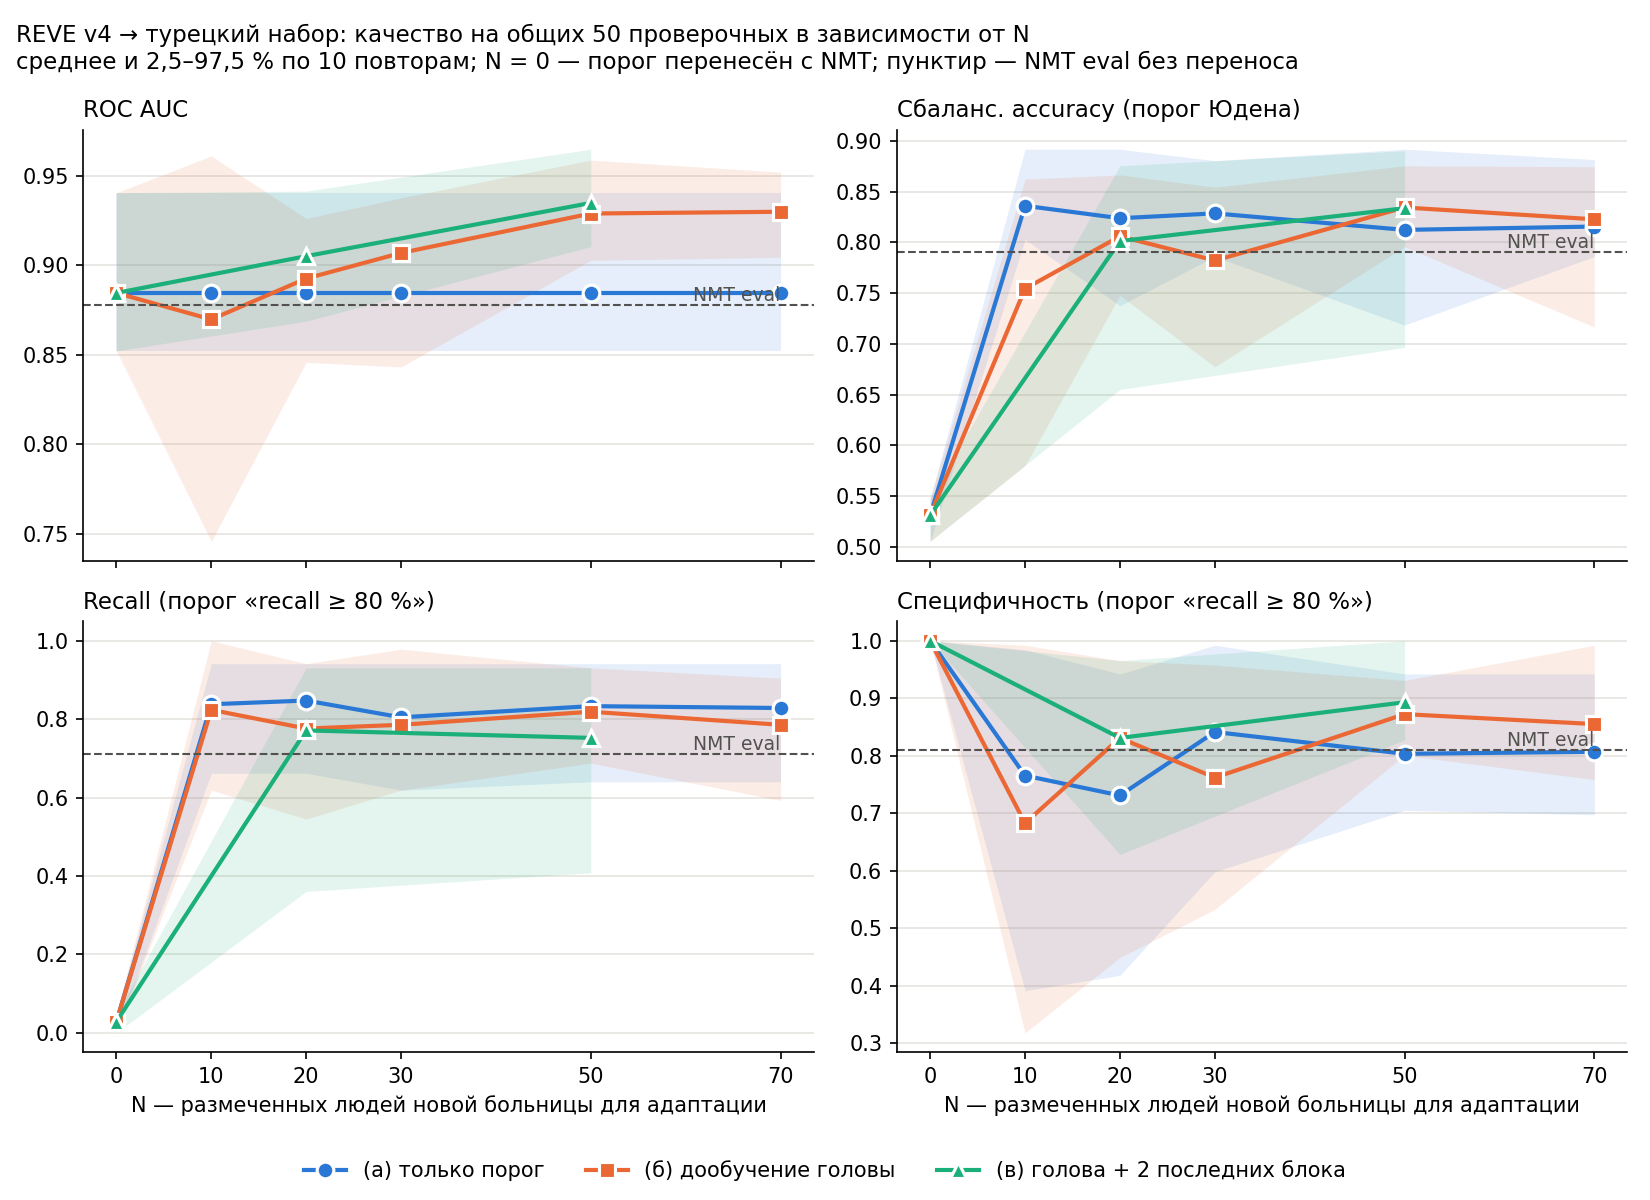

In [23]:
display(Image(f"{ASSETS}/reve_fewshot_curve.png", width=1100))

- **N = 0:** ROC AUC 0,885 не падает, но порог с NMT не подходит — сбаланс. accuracy 0,53.
- **N = 10–20:** настройка одного порога даёт 0,82–0,84. Дальше почти не растёт.
- **N ≥ 50:** дообучение модели поднимает ROC AUC на 0,044–0,050, во всех 10 повторах. При N = 10–30 дообучение хуже простой настройки порога.

**Что говорим заказчику:** 10–20 размеченных записей клиники — настроить порог, от 50 — имеет смысл дообучать модель.

## 8. Можно ли recall 0,85–0,9 и чего это стоит
Сколько специфичности остаётся, если сдвинуть порог до нужного recall. **Порог подобран по этим же данным, поэтому это верхняя оценка**, а не результат на новых людях.

In [24]:
rows = []
for name, col in [("REVE v4", "reve4_ens_prob"), ("Пара REVE + EEG-DINO", "ens_reve4_dino2")]:
    for ds, lab in [("nmt_eval", "NMT eval"), ("turkey", "Турция"), ("epieeg60", "EpiEEG-60")]:
        d = PP[PP.dataset == ds]; f, t, _ = roc_curve(d.y, d[col]); r = dict(модель=name, больница=lab)
        for R in [0.80, 0.85, 0.90]:
            r[f"специфичность при recall {R:.2f}"] = round(1 - f[np.argmax(t >= R)], 2)
        rows.append(r)
display(pd.DataFrame(rows).set_index(["модель", "больница"]))

специфичность при recall 0.80  специфичность при recall 0.85  специфичность при recall 0.90
модель               больница                                                                                              
REVE v4              NMT eval                            0.82                           0.77                           0.76
                     Турция                              0.87                           0.82                           0.80
                     EpiEEG-60                           0.50                           0.47                           0.47
Пара REVE + EEG-DINO NMT eval                            0.88                           0.87                           0.77
                     Турция                              0.96                           0.92                           0.80
                     EpiEEG-60                           0.62                           0.44                           0.19

- **Пакистан и Турция:** recall 0,85 достижим при специфичности 0,87–0,92 у пары, recall 0,9 — при 0,77–0,80.
- **Бангладеш:** recall 0,85 — специфичность 0,44, recall 0,9 — 0,19. На трудной больнице такого recall модель честно не даёт.
- **С порогом, настроенным по 20 людям** (то есть в реальной работе), в Турции у пары в среднем recall 0,77–0,79 при специфичности 0,89–0,91, разброс между выборками большой.

**Вывод:** цель recall ≥ 0,85 выполнима там, где ROC AUC около 0,9. Там, где 0,76, нужна более сильная модель или данные клиники (раздел 7).

## 9. Метрики в статьях: к чему стремимся
Все цифры сверены по статьям, подробно: `Сравнение_со_статьями/Сравнение_метрик_2026-11-01.md`.

| Работа | Данные | Контроль | Проверка | Результат | Сравнимо с нами? |
|---|---|---|---|---|---|
| DeepEpilepsy, Brain Comm 2025 | 118 пациентов, CHUM | пациенты с подозрением | своя больница | AUC **0,76**; с разрядами **0,83**: 73 % / 75 % | контроль труднее, больница своя |
| Erasmus MC, arXiv 2026 | 141, без разрядов | после первого приступа | своя больница | AUC **0,79** | ближе всего к реальной задаче |
| Thangavel, J Neural Eng 2022 | 6 центров | норма по заключению | вынос центра | AUC **0,84** | похоже, но с детектором разрядов |
| Khan 2022 (авторы NMT) | NMT, тот же тест | норма | внутри набора | AUC **0,86** | **прямо сравнимо: у нас 0,92** |
| Tasci 2023 (авторы Турции) | 121 | здоровые | внутри набора, по людям | accuracy **79 %** | у нас без обучения на нём сбаланс. accuracy 0,84 |
| CLEF, arXiv 2026 | TUEP, внутри набора | TUEP | предобучены на TUH | REVE **0,90**, BIOT 0,82, LaBraM 0,86 | завышено для нас |
| EEG-Bench, arXiv 2025 | TUEP, 200 | TUEP | по людям | сбаланс. accuracy LaBraM **0,57**, BENDR 0,74 | на TUEP модели могут провалиться |

**Честная цель.** Контроль — пациенты с подозрением, новая больница: **ROC AUC ≈ 0,80, recall 70–75 % при специфичности ≈ 75 %**. Больные против здоровых в чужой больнице: удерживать ≥ 0,85. Наши 0,92–0,94 нельзя ставить рядом с 0,76–0,79: у нас в контроле здоровые. Когда условия сближаются (Бангладеш), мы получаем те же 0,76. Проверит это TUEP.

## 10. Г2: где мы и к чему стремимся
Вживую показывают Дарья (nnU-Net: кривые потерь `progress.png`, снимки) и Ярослава (MELD Graph).

| Bonn | Очаг найден у пациента | Dice | Здоровые с ложными находками |
|---|---|---|---|
| **Наш nnU-Net** (T1 + FLAIR, 50 эпох, 1 фолд; 13 + 21 чел.) | 69 % (хватало 1 вокселя) | 0,145 | 100 % (считался любой воксель) |
| **Наш MELD Graph** (только T1; 3 + 3 чел.) | 2 из 3 | 0,31 и 0,50 | 2 из 3 |
| nnU-Net, T1 + FLAIR (Ghosh 2026; 5 фолдов) | 67 % | 0,36 | 12 % |
| MELD Graph (JAMA Neurol 2025, независимая группа) | 72 %, допуск 20 мм | IoU 0,36 | 44 % (специфичность 56 %) |
| Эксперты-рентгенологи, тот же набор (Walger 2025) | 68 % | — | — |

**Цель:** очаг найден ≈ 70 %, ложные находки ≤ 20–40 % здоровых, Dice 0,3–0,4.
**Что мешает сравнить сейчас:** у нас 50 эпох вместо стандартных 1000, один фолд и самые жёсткие правила подсчёта ложных находок. **Дальше:** полное обучение на одной карте рабочей машины, подсчёт по правилам статей (кластеры, отсечение мелких, допуск 20 мм), MELD Graph на тестовой части Bonn.

## 11. Что дальше
1. **TUEP** (доступ одобрен 02.11): скачать на рабочую машину, прогнать REVE и EEG-DINO; BIOT и EEGPT — контроль, потому что они архив TUH не видели, а REVE, EEG-DINO и LaBraM видели. Отдельно — больные без разрядов.
2. **08.11:** выбор модели по первым цифрам на TUEP, если данные успеют.
3. **Проверка на ложные тревоги:** открытые наборы с другими болезнями, только для проверки (ЭЭГ: деменция ds004504, Паркинсон; МРТ: IDEAS без ФКД, MR-ART).
4. **Г2:** эталонные метрики к 11.11.